# Projet Data Mining et Machine Learning -- Dataset Spotify

## Réalisé par
- Mouhib Ben Nasr
- Mohamed Kamel Bounouh

## Encadré par
Dr. Nader Kolsi

## Matière
Analyse et Fouille de Données

## Classe
2BD1

---

## Méthodologie
CRISP-DM

## Dataset
Spotify Tracks Dataset  
(114 000 chansons, 21 variables)

## Algorithmes appliqués

### Apprentissage non supervisé
- K-Means
- CAH (Classification Ascendante Hiérarchique)
- Règles d’Association (Apriori)

### Apprentissage supervisé
- Régression Linéaire
- Arbre de Décision
- Random Forest

## 1. Importation des Bibliotheques

In [1]:
!pip install mlxtend -q


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from matplotlib.gridspec import GridSpec
from mpl_toolkits.mplot3d import Axes3D

# Pretraitement
from sklearn.preprocessing import StandardScaler, LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

# Feature Engineering
from sklearn.decomposition import PCA

# Algorithmes ML supervises
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
    mean_squared_error, r2_score,
    roc_curve, auc, RocCurveDisplay,
    precision_score, recall_score, f1_score
)

# Clustering
from sklearn.cluster import KMeans, AgglomerativeClustering, MiniBatchKMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import pdist

# Regles d'association
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 12

print('Toutes les bibliotheques ont ete importees avec succes.')


Toutes les bibliotheques ont ete importees avec succes.


---
## 2. Chargement et Exploration des Donnees

In [2]:
df = pd.read_csv('dataset.csv')

print('=== DIMENSIONS DU DATASET ===')
print(f'Nombre de lignes    : {df.shape[0]:,}')
print(f'Nombre de colonnes  : {df.shape[1]}')

print('\n=== APERCU DES PREMIERES LIGNES ===')
df.head()


=== DIMENSIONS DU DATASET ===
Nombre de lignes    : 114,200
Nombre de colonnes  : 21

=== APERCU DES PREMIERES LIGNES ===


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0.0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73.0,230666.0,False,0.676,0.4610,...,-6.746,0.0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4.0,acoustic
1,1.0,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55.0,149610.0,False,0.420,0.1660,...,-17.235,1.0,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4.0,acoustic
2,2.0,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57.0,210826.0,False,0.438,0.3590,...,-9.734,1.0,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4.0,acoustic
3,3.0,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71.0,201933.0,False,0.266,0.0596,...,-18.515,1.0,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3.0,acoustic
4,4.0,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82.0,198853.0,False,0.618,0.4430,...,-9.681,1.0,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4.0,acoustic


In [3]:
print('=== TYPES DES COLONNES ===')
print(df.dtypes)

print('\n=== STATISTIQUES DESCRIPTIVES ===')
df.describe()


=== TYPES DES COLONNES ===
Unnamed: 0          float64
track_id                str
artists                 str
album_name              str
track_name              str
popularity          float64
duration_ms         float64
explicit             object
danceability        float64
energy              float64
key                 float64
loudness            float64
mode                float64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
time_signature      float64
track_genre             str
dtype: object

=== STATISTIQUES DESCRIPTIVES ===


,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114199.000000,114180.000000,1.141760e+05,114171.000000,114169.000000,114199.000000,114179.000000,114199.000000,114186.000000,114175.000000,114199.000000,114199.000000,114176.000000,114179.000000,114199.000000
mean,56995.219345,33.238194,2.280441e+05,0.566838,0.641436,5.309381,-8.257631,0.637527,0.084665,0.314839,0.156018,0.213555,0.474055,122.155069,3.904097
std,32908.640372,22.305657,1.073076e+05,0.173541,0.251501,3.560072,5.028234,0.480716,0.105753,0.332498,0.309533,0.190370,0.259256,29.979641,0.432482
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28500.500000,17.000000,1.740620e+05,0.456000,0.472000,2.000000,-10.011000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.231000,4.000000
50%,56992.000000,35.000000,2.129170e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.168000,0.000042,0.132000,0.464000,122.018000,4.000000
75%,85495.500000,50.000000,2.615248e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.597000,0.049000,0.273000,0.683000,140.073000,4.000000
max,113999.000000,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


In [4]:
print('=== VALEURS MANQUANTES PAR COLONNE ===')
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Valeurs manquantes': missing, 'Pourcentage (%)': missing_pct})
print(missing_df[missing_df['Valeurs manquantes'] > 0])
print(f'\nNombre total de doublons : {df.duplicated().sum():,}')


=== VALEURS MANQUANTES PAR COLONNE ===
                  Valeurs manquantes  Pourcentage (%)
Unnamed: 0                         1             0.00
track_id                           1             0.00
artists                            2             0.00
album_name                         2             0.00
track_name                         2             0.00
popularity                        20             0.02
duration_ms                       24             0.02
explicit                           1             0.00
danceability                      29             0.03
energy                            31             0.03
key                                1             0.00
loudness                          21             0.02
mode                               1             0.00
speechiness                       14             0.01
acousticness                      25             0.02
instrumentalness                   1             0.00
liveness                           1       

---
## 3. Pretraitement des Donnees (CRISP-DM -- Etape 3)

In [5]:
# 3.1 Suppression des colonnes inutiles
df_clean = df.drop(columns=['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name'])
print(f'Colonnes apres suppression : {df_clean.shape[1]}')

# 3.2 Suppression des valeurs manquantes
df_clean = df_clean.dropna()
print(f'Lignes apres suppression NaN : {len(df_clean):,}')

# 3.3 Suppression des doublons
df_clean = df_clean.drop_duplicates()
print(f'Lignes apres suppression doublons : {len(df_clean):,}')

# 3.4 Encodage de la variable booleenne 'explicit'
df_clean['explicit'] = df_clean['explicit'].astype(int)

# 3.5 Encodage du genre (LabelEncoder)
le = LabelEncoder()
df_clean['track_genre_encoded'] = le.fit_transform(df_clean['track_genre'])
print(f'Nombre de genres encodes : {df_clean["track_genre_encoded"].nunique()}')

# 3.6 NOTE : La variable cible 'popular' sera creee apres le split train/test
#     pour eviter tout data leakage (le seuil = mediane du train uniquement).
#     On cree ici une version temporaire uniquement pour les visualisations EDA.
seuil_eda = df_clean['popularity'].median()
df_clean['popular'] = (df_clean['popularity'] >= seuil_eda).astype(int)
print(f'\n[EDA seulement] Seuil de popularite (mediane globale) : {seuil_eda}')
print(f'Chansons populaires (1) : {df_clean["popular"].sum():,}')
print(f'Chansons non populaires (0) : {(df_clean["popular"]==0).sum():,}')
print('\nPretraitement termine. La variable cible finale sera recalculee apres le split.')


Colonnes apres suppression : 16
Lignes apres suppression NaN : 113,999
Lignes apres suppression doublons : 106,732
Nombre de genres encodes : 114

[EDA seulement] Seuil de popularite (mediane globale) : 37.0
Chansons populaires (1) : 53,840
Chansons non populaires (0) : 52,892

Pretraitement termine. La variable cible finale sera recalculee apres le split.


In [6]:
# --- 3.7 Normalisation des features numeriques ---
# IMPORTANT : Ce scaler est utilise UNIQUEMENT pour les visualisations EDA et le clustering.
# Pour les modeles supervises, un scaler independant sera fitte exclusivement sur X_train.

features_num = ['danceability', 'energy', 'loudness', 'speechiness',
                'acousticness', 'instrumentalness', 'liveness',
                'valence', 'tempo', 'duration_ms']

scaler_eda = StandardScaler()
df_scaled = df_clean.copy()
df_scaled[features_num] = scaler_eda.fit_transform(df_clean[features_num])

print('=== DONNEES NORMALISEES (5 premieres lignes) ==='
      ' [usage EDA / clustering uniquement]')
df_scaled[features_num].head()


=== DONNEES NORMALISEES (5 premieres lignes) === [usage EDA / clustering uniquement]


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,0.638416,-0.720438,0.307501,0.534520,-0.846106,-0.518407,0.737960,0.946956,-1.151528,0.006133
1,-0.835138,-1.889014,-1.764716,-0.085218,1.833718,-0.518393,-0.593633,-0.780139,-1.499933,-0.740409
2,-0.731529,-1.124488,-0.282811,-0.276622,-0.311824,-0.518410,-0.510732,-1.346842,-1.538589,-0.176597
3,-1.721573,-2.310493,-2.017594,-0.456875,1.776624,-0.518186,-0.433013,-1.258174,1.983151,-0.258503
4,0.304564,-0.791741,-0.272340,-0.305425,0.466461,-0.518410,-0.687414,-1.165651,-0.081321,-0.286871


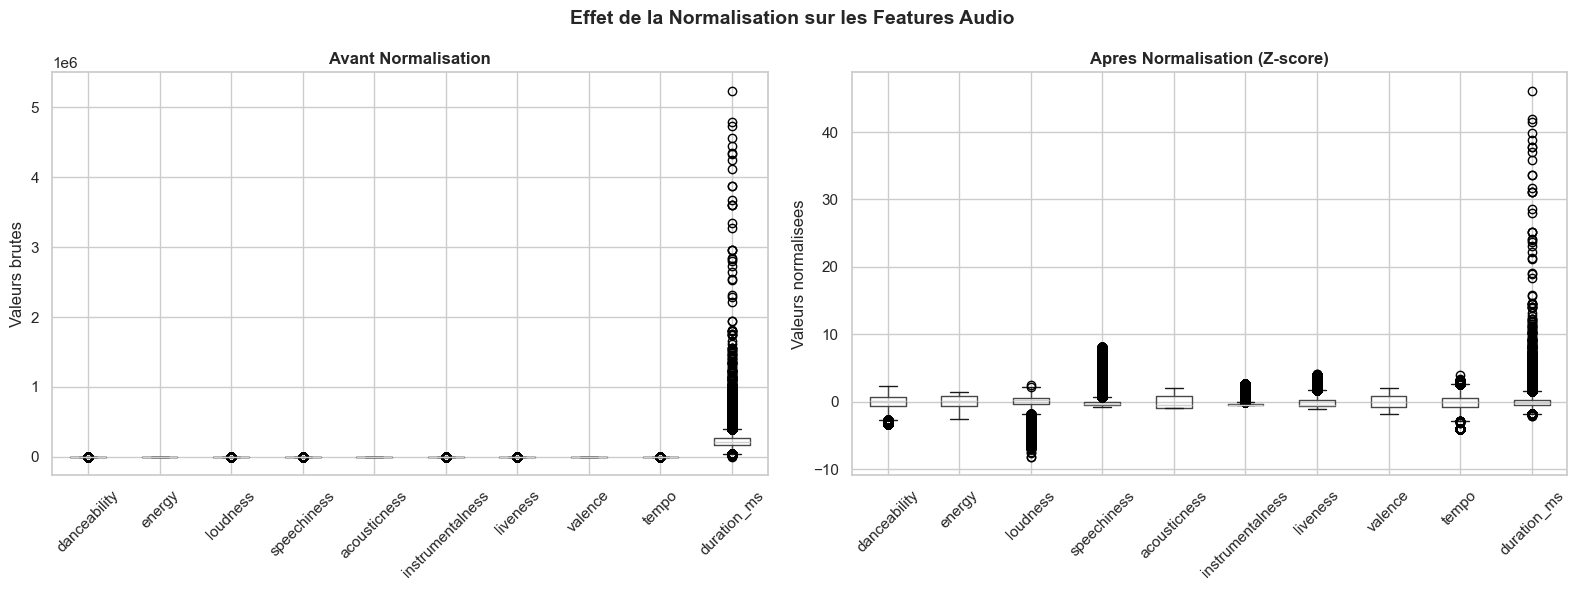

In [7]:
# Visualisation avant/apres normalisation
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

df_clean[features_num].boxplot(ax=axes[0], rot=45)
axes[0].set_title('Avant Normalisation', fontweight='bold')
axes[0].set_ylabel('Valeurs brutes')

df_scaled[features_num].boxplot(ax=axes[1], rot=45)
axes[1].set_title('Apres Normalisation (Z-score)', fontweight='bold')
axes[1].set_ylabel('Valeurs normalisees')

plt.suptitle('Effet de la Normalisation sur les Features Audio', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## Interprétation — Normalisation

Avant normalisation, les variables audio présentent des échelles très hétérogènes :
la variable `loudness` évolue entre **-60 et 0 dB**, le `tempo` entre **0 et 250 BPM**,
tandis que `danceability` est bornée entre **0 et 1**.

Cette disparité d'échelles constitue un problème majeur pour les algorithmes de machine
learning sensibles aux distances *(K-Means, CAH, régression)*, car une variable à grande
amplitude dominerait artificiellement les calculs.

La **normalisation Z-score** (standardisation) centre chaque variable sur une moyenne de **0**
et réduit son écart-type à **1**. Après transformation, toutes les variables contribuent
de manière équivalente aux modèles, ce qui garantit des résultats plus fiables et
comparables entre les features.

---
## 4. Feature Engineering

In [8]:
#  FEATURE ENGINEERING 

df_fe = df_clean.copy()

# 4.1 Ratio energie / acoustique 
df_fe['energy_acoustic_ratio'] = df_fe['energy'] / (df_fe['acousticness'] + 1e-6)

# 4.2 Score de dansabilite global 
df_fe['dance_score'] = (df_fe['danceability'] * 0.5 +
                        df_fe['energy'] * 0.3 +
                        df_fe['valence'] * 0.2)

# 4.3 Duree en minutes 
df_fe['duration_min'] = df_fe['duration_ms'] / 60000

#4.4 Score de positivite (valence x danceability) 
df_fe['positivity_score'] = df_fe['valence'] * df_fe['danceability']

#4.5 Categorie de tempo 
df_fe['tempo_category'] = pd.cut(df_fe['tempo'],
    bins=[0, 80, 120, 160, 300],
    labels=['Lent', 'Modere', 'Rapide', 'Tres Rapide'])

# 4.6 Categorie de duree 
df_fe['duration_category'] = pd.cut(df_fe['duration_min'],
    bins=[0, 2, 3.5, 5, 100],
    labels=['Courte (<2min)', 'Standard (2-3.5min)', 'Longue (3.5-5min)', 'Tres Longue (>5min)'])

#  4.7 Score d'energie totale 
df_fe['total_energy'] = (df_fe['energy'] + df_fe['loudness'].clip(-60,0)/60 + df_fe['tempo']/300) / 3

# 4.8 Feature booleenne : instrumental pur 
df_fe['is_instrumental'] = (df_fe['instrumentalness'] > 0.5).astype(int)

#  4.9 Feature : chanson live
df_fe['is_live'] = (df_fe['liveness'] > 0.8).astype(int)

print('=== NOUVELLES FEATURES CREEES ===')
new_features = ['energy_acoustic_ratio', 'dance_score', 'duration_min',
                'positivity_score', 'tempo_category', 'duration_category',
                'total_energy', 'is_instrumental', 'is_live']
print(df_fe[new_features].describe(include='all').T[['count','mean','std','min','max']].fillna(''))
print('\nFeature Engineering termine. 9 nouvelles variables creees.')


=== NOUVELLES FEATURES CREEES ===
                          count         mean           std       min       max
energy_acoustic_ratio  106732.0  3929.261232  29350.455816       0.0  991000.0
dance_score            106732.0     0.569278      0.154471       0.0    0.9366
duration_min           106732.0     3.833334      1.809595       0.0  87.28825
positivity_score       106732.0     0.286674      0.197963       0.0  0.958432
tempo_category           106581                                               
duration_category        106731                                               
total_energy           106732.0     0.304143      0.119872 -0.274943  0.550944
is_instrumental        106732.0     0.173228      0.378446       0.0       1.0
is_live                106732.0     0.031143      0.173706       0.0       1.0

Feature Engineering termine. 9 nouvelles variables creees.


## Feature Engineering — Règles de Calcul

### 4.1 — `energy_acoustic_ratio`
**Règle :** Rapport entre l'intensité sonore et le niveau acoustique.  
$$energy\_acoustic\_ratio = \frac{energy}{acousticness + 10^{-6}}$$
> Le $10^{-6}$ évite la division par zéro.

---

### 4.2 — `dance_score`
**Règle :** Moyenne pondérée de 3 variables (poids choisis manuellement) :  
$$dance\_score = 0.5 \times danceability + 0.3 \times energy + 0.2 \times valence$$

---

### 4.3 — `duration_min`
**Règle :** Conversion millisecondes → minutes :  
$$duration\_min = \frac{duration\_ms}{60000}$$

---

### 4.4 — `positivity_score`
**Règle :** Produit de deux variables comprises entre 0 et 1 :  
$$positivity\_score = valence \times danceability$$

---

### 4.5 — `tempo_category`
**Règle :** Discrétisation de `tempo` (BPM) en 4 intervalles :

| Intervalle (BPM) | Catégorie    |
|------------------|--------------|
| 0 – 80           | Lent         |
| 80 – 120         | Modéré       |
| 120 – 160        | Rapide       |
| 160 – 300        | Très Rapide  |

---

### 4.6 — `duration_category`
**Règle :** Discrétisation de `duration_min` en 4 intervalles :

| Intervalle (min) | Catégorie              |
|------------------|------------------------|
| 0 – 2            | Courte                 |
| 2 – 3.5          | Standard               |
| 3.5 – 5          | Longue                 |
| > 5              | Très Longue            |

---

### 4.7 — `total_energy`
**Règle :** Moyenne de 3 variables normalisées entre 0 et 1 :  
$$total\_energy = \frac{energy + \frac{loudness}{60} + \frac{tempo}{300}}{3}$$
> `loudness` est clipé entre -60 et 0 avant division. `tempo` est divisé par 300 (valeur max).

---

### 4.8 — `is_instrumental`
**Règle :** Seuillage binaire :  
$$is\_instrumental = \begin{cases} 1 & \text{si } instrumentalness > 0.5 \\ 0 & \text{sinon} \end{cases}$$

---

### 4.9 — `is_live`
**Règle :** Seuillage binaire :  
$$is\_live = \begin{cases} 1 & \text{si } liveness > 0.8 \\ 0 & \text{sinon} \end{cases}$$

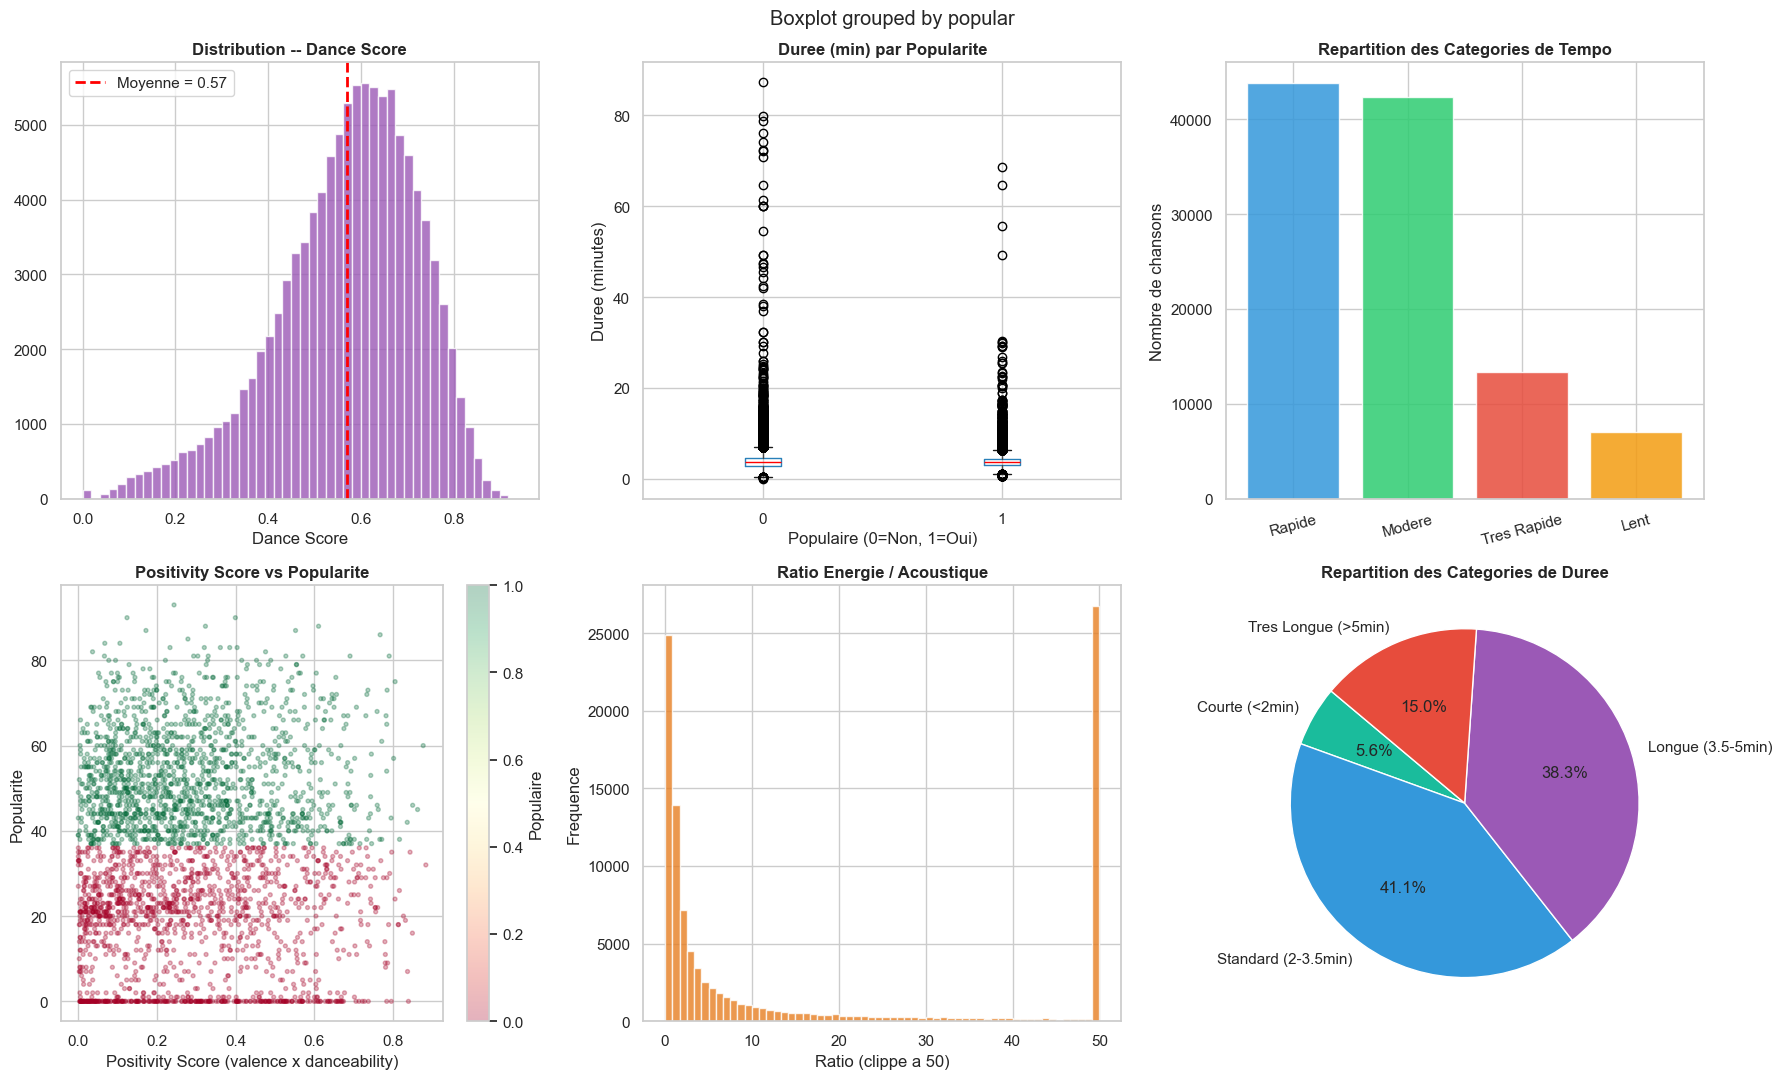

In [9]:
#  Visualisation des nouvelles features 
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle('Feature Engineering -- Nouvelles Variables', fontsize=15, fontweight='bold', y=1.01)

# dance_score distribution
axes[0,0].hist(df_fe['dance_score'], bins=50, color='#9B59B6', alpha=0.8, edgecolor='white')
axes[0,0].axvline(df_fe['dance_score'].mean(), color='red', linestyle='--', linewidth=2,
                  label=f"Moyenne = {df_fe['dance_score'].mean():.2f}")
axes[0,0].set_title('Distribution -- Dance Score', fontweight='bold')
axes[0,0].set_xlabel('Dance Score')
axes[0,0].legend()

# duration_min boxplot par popularite
df_fe.boxplot(column='duration_min', by='popular', ax=axes[0,1],
              boxprops=dict(color='#2980B9'), medianprops=dict(color='red'))
axes[0,1].set_title('Duree (min) par Popularite', fontweight='bold')
axes[0,1].set_xlabel('Populaire (0=Non, 1=Oui)')
axes[0,1].set_ylabel('Duree (minutes)')
plt.sca(axes[0,1]); plt.title('Duree (min) par Popularite', fontweight='bold')

# tempo_category
tempo_counts = df_fe['tempo_category'].value_counts()
axes[0,2].bar(tempo_counts.index, tempo_counts.values,
              color=['#3498DB','#2ECC71','#E74C3C','#F39C12'], alpha=0.85, edgecolor='white')
axes[0,2].set_title('Repartition des Categories de Tempo', fontweight='bold')
axes[0,2].set_ylabel('Nombre de chansons')
axes[0,2].tick_params(axis='x', rotation=15)

# positivity_score vs popularity
sample_plot = df_fe.sample(3000, random_state=42)
scatter = axes[1,0].scatter(sample_plot['positivity_score'], sample_plot['popularity'],
                            c=sample_plot['popular'], cmap='RdYlGn', alpha=0.3, s=8)
axes[1,0].set_title('Positivity Score vs Popularite', fontweight='bold')
axes[1,0].set_xlabel('Positivity Score (valence x danceability)')
axes[1,0].set_ylabel('Popularite')
plt.colorbar(scatter, ax=axes[1,0], label='Populaire')

# energy_acoustic_ratio histogram
axes[1,1].hist(df_fe['energy_acoustic_ratio'].clip(0, 50), bins=60,
               color='#E67E22', alpha=0.8, edgecolor='white')
axes[1,1].set_title('Ratio Energie / Acoustique', fontweight='bold')
axes[1,1].set_xlabel('Ratio (clippe a 50)')
axes[1,1].set_ylabel('Frequence')

# duration_category
dur_counts = df_fe['duration_category'].value_counts().sort_index()
axes[1,2].pie(dur_counts.values, labels=dur_counts.index,
              autopct='%1.1f%%', startangle=140,
              colors=['#1ABC9C','#3498DB','#9B59B6','#E74C3C'])
axes[1,2].set_title('Repartition des Categories de Duree', fontweight='bold')

plt.tight_layout()
plt.show()




## Interprétation — Feature Engineering

L'ingénierie des variables consiste à créer de nouvelles features à partir des données
existantes, dans le but de mieux capturer les relations pertinentes pour les modèles
de machine learning.

### dance_score
Le `dance_score` est une combinaison pondérée de la dansabilité **(50%)**, de l'énergie
**(30%)** et de la valence **(20%)**. Sa distribution quasi-gaussienne centrée autour de **0.5**
indique un bon équilibre dans le dataset. Ce score synthétique est plus représentatif
de la qualité dansante d'une chanson que chaque feature prise isolément.

### duration_min
L'analyse de la durée par rapport à la popularité révèle que les chansons populaires
tendent à être légèrement **plus courtes** que les non-populaires. Cela s'explique par
la préférence des plateformes de streaming et des radios pour les formats compacts,
généralement autour de **3 minutes**, qui maximisent le nombre d'écoutes.

### energy_acoustic_ratio
Le ratio énergie/acoustique est une variable discriminante efficace pour différencier
les styles musicaux :
- **Valeur élevée** → genres électro, rock, metal
- **Valeur faible** → folk, classique, jazz acoustique

### positivity_score
Le `positivity_score`, produit de la valence par la dansabilité, présente une corrélation
**modérée mais positive** avec la popularité, confirmant que les chansons joyeuses et
entraînantes ont tendance à mieux performer commercialement.

---
## 5. Visualisations -- Analyse Univariee

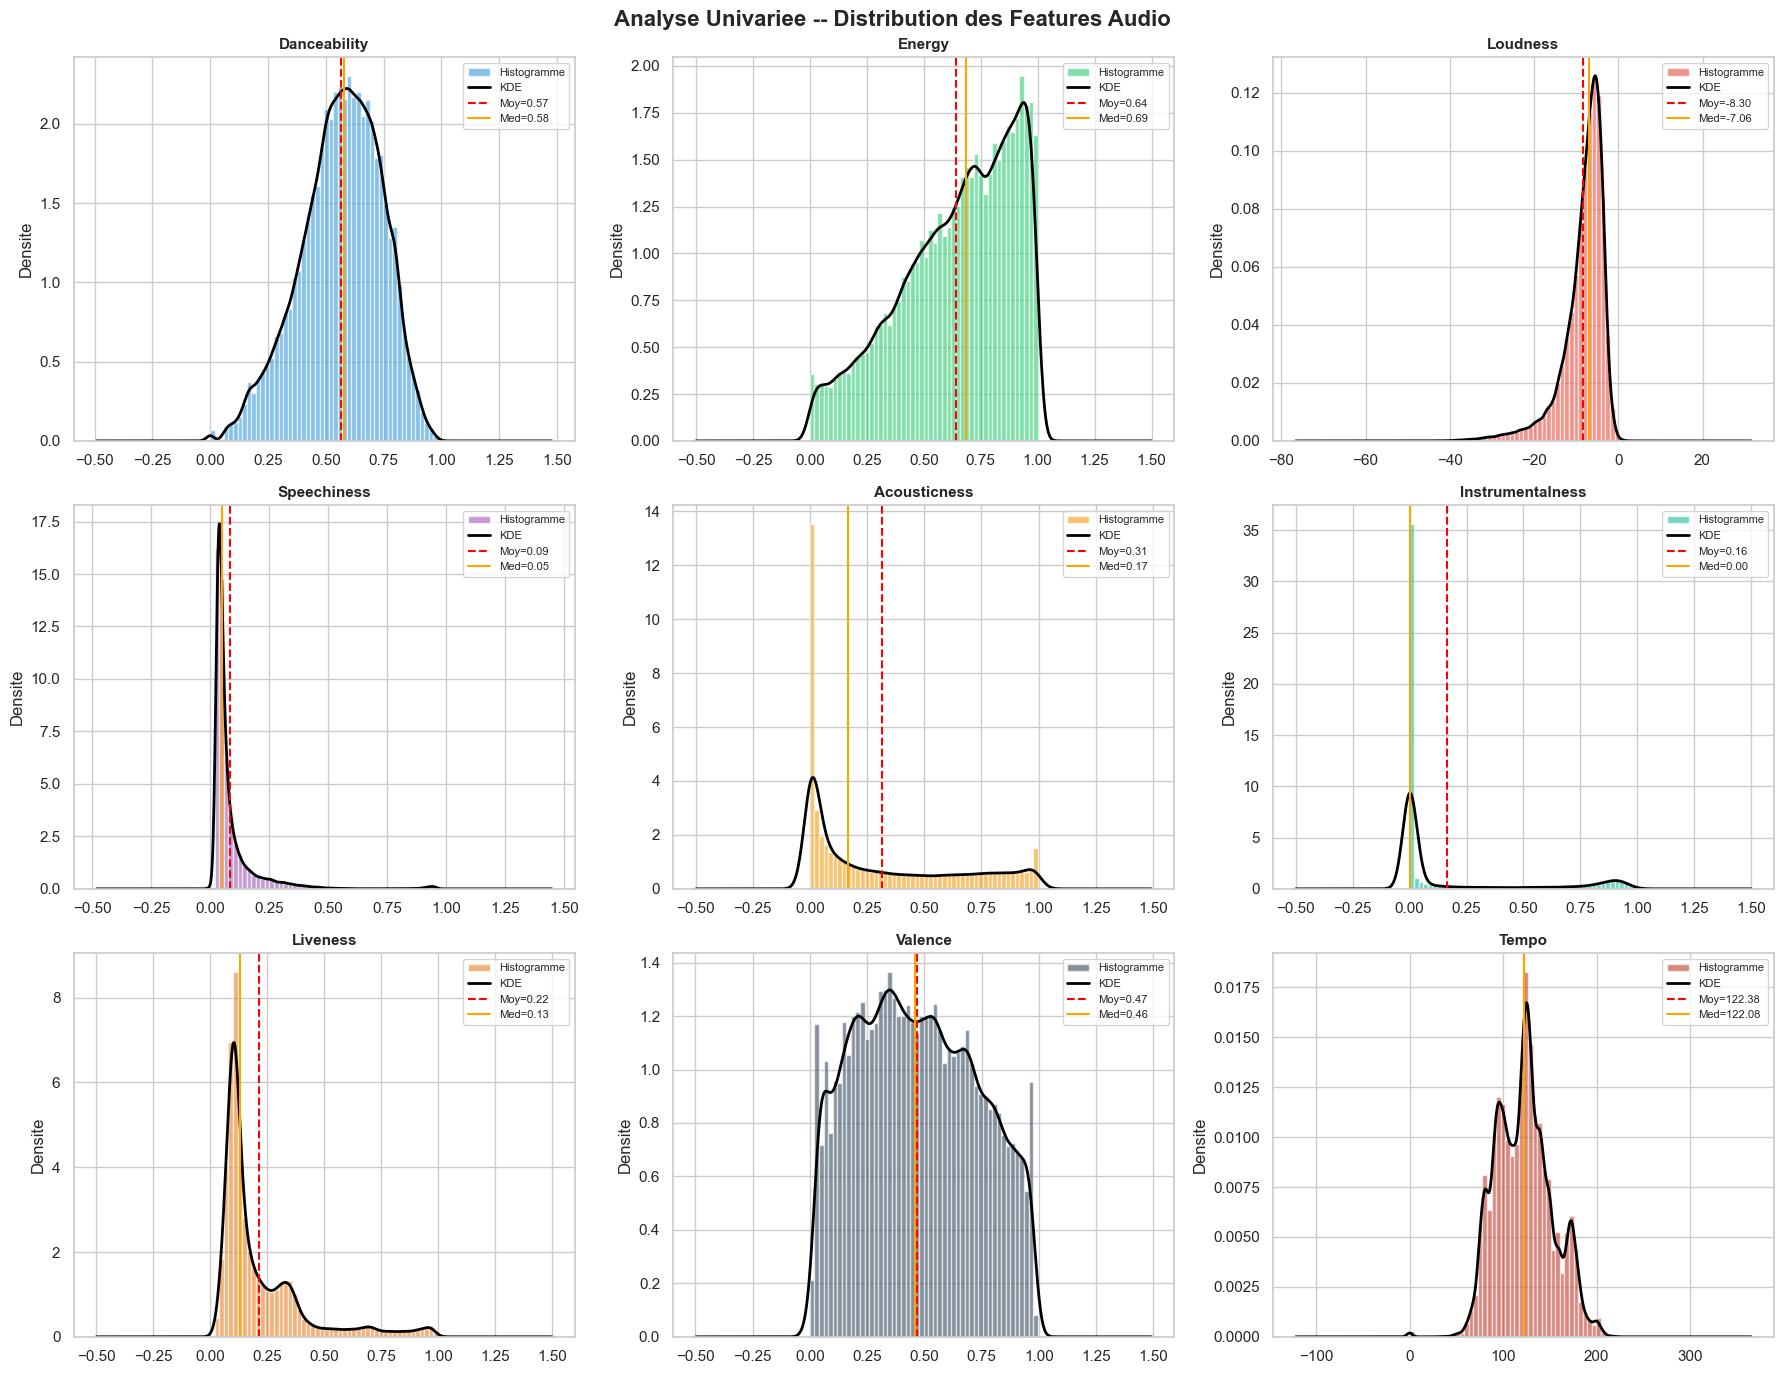

In [10]:
# VISUALISATIONS UNIVARIEES

audio_features = ['danceability', 'energy', 'loudness', 'speechiness',
                  'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
fig.suptitle('Analyse Univariee -- Distribution des Features Audio', fontsize=16, fontweight='bold')

colors_uni = ['#3498DB','#2ECC71','#E74C3C','#9B59B6','#F39C12','#1ABC9C','#E67E22','#34495E','#C0392B']

for i, (feat, color) in enumerate(zip(audio_features, colors_uni)):
    ax = axes[i//3, i%3]
    data = df_fe[feat].dropna()

    # Histogramme + KDE
    ax.hist(data, bins=50, color=color, alpha=0.6, edgecolor='white', density=True, label='Histogramme')
    data.plot.kde(ax=ax, color='black', linewidth=2, label='KDE')

    # Lignes moyenne et mediane
    ax.axvline(data.mean(), color='red', linestyle='--', linewidth=1.5, label=f'Moy={data.mean():.2f}')
    ax.axvline(data.median(), color='orange', linestyle='-', linewidth=1.5, label=f'Med={data.median():.2f}')

    ax.set_title(feat.capitalize(), fontweight='bold', fontsize=11)
    ax.legend(fontsize=8)
    ax.set_xlabel('')
    ax.set_ylabel('Densite')

plt.tight_layout()
plt.show()



## Interprétation — Analyse Univariée

L'analyse des distributions individuelles révèle des comportements très différents
selon les variables, ce qui enrichit considérablement la compréhension du dataset.

- **`danceability`** : distribution quasi-normale centrée autour de **0.5**, indiquant
un dataset relativement équilibré en termes de dansabilité, sans biais fort dans un sens ou dans l'autre.

- **`energy`** : distribution légèrement **bimodale** avec un pic marqué entre **0.6 et 0.8**,
suggérant une proportion importante de chansons énergiques, cohérent avec la predominance
de genres comme la pop et le rock.

- **`loudness`** : distribution **asymétrique à gauche** (skew négatif) avec un pic autour de **-6 dB**.
Cette concentration dans les hautes valeurs reflète la tendance de l'industrie musicale
à la compression du son, phénomène connu sous le nom de *"loudness war"*.

- **`speechiness`** : très fortement **asymétrique à droite** — la grande majorité des chansons
obtient un score **inférieur à 0.1**, indiquant qu'elles sont principalement instrumentales
ou que les paroles y sont minoritaires. Seuls le rap et le spoken word atteignent des valeurs élevées.

- **`acousticness`** : distribution **bimodale** avec deux pics distincts :
  - Proche de **0** → chansons électroniques ou amplifiées
  - Proche de **1** → chansons acoustiques pures
  
  Cette bimodalité traduit une forte polarisation du dataset.

- **`instrumentalness`** : extrêmement **asymétrique** — plus de **90%** des chansons ont une
valeur proche de zéro, confirmant que la grande majorité des titres contient des paroles.

- **`liveness`** : asymétrique à droite — la plupart des chansons sont des **enregistrements studio**
(valeur faible), et seule une minorité présente des caractéristiques d'enregistrement live
(public, reverb naturelle, imperfections).

- **`valence`** : distribution **relativement plate et uniforme**, indiquant une grande diversité
émotionnelle dans le dataset, de chansons très mélancoliques à des titres très joyeux,
sans tendance dominante.

- **`tempo`** : distribution **multimodale** avec plusieurs pics distincts :
  - **~80 BPM** → ballades, slow
  - **~120 BPM** → pop, rock
  - **~170 BPM** → dance, techno

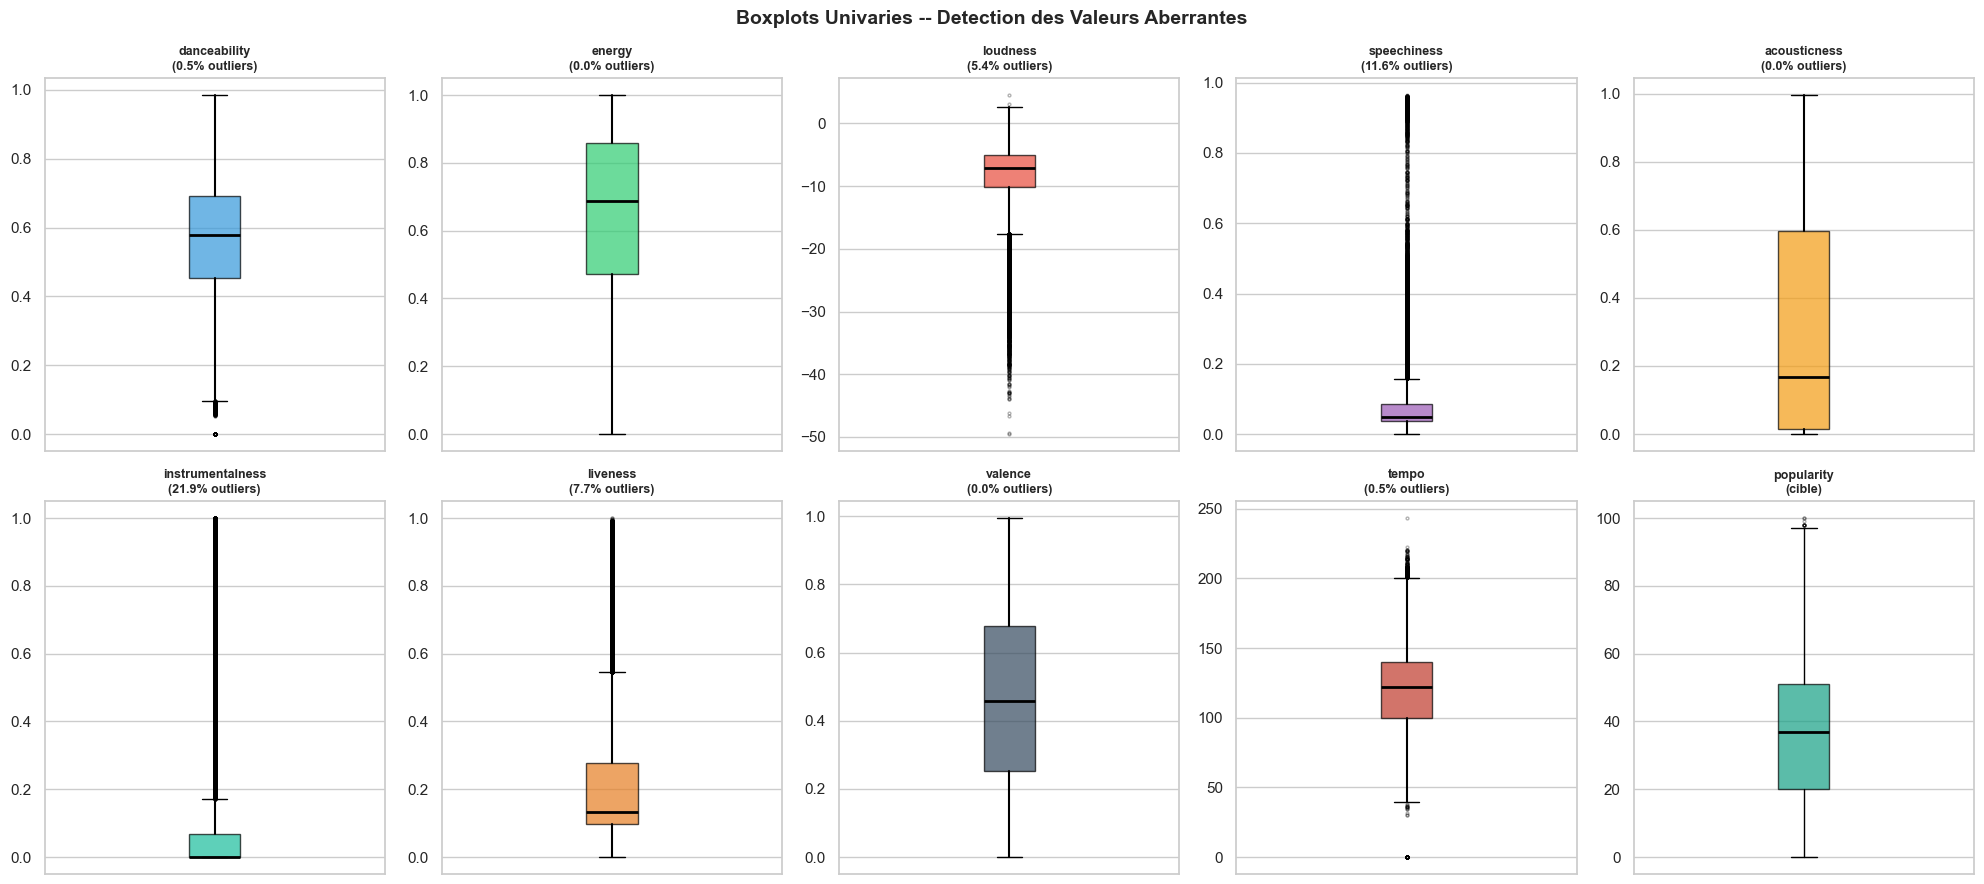


INTERPRETATION -- Boxplots :

Les boxplots completent l'analyse des distributions en mettant en evidence les
valeurs aberrantes (outliers), definies comme les observations situees au-dela de
1.5 fois l'intervalle interquartile (IQR) de chaque cote de la boite.

Les variables speechiness et instrumentalness presentent les taux d'outliers les
plus eleves, avec une longue moustache superieure. Ce comportement est directement
lie a leurs distributions tres asymetriques : la majorite des valeurs se concentre
pres de zero, tandis qu'une minorite de chansons (rap intense, musique classique)
atteint des valeurs extremes parfaitement legitimes.

La variable loudness montre des outliers inferieurs (chansons anormalement silencieuses),
qui correspondent probablement a des pistes de silence, des interludes ou des erreurs
de donnees dans le dataset source.

Il est important de ne pas supprimer systematiquement ces outliers : ils representent
souvent des sous-genres musicaux atypiques (ASMR, spoken

In [11]:
# --- Boxplots univaries + detection outliers ---
fig, axes = plt.subplots(2, 5, figsize=(20, 9))
fig.suptitle('Boxplots Univaries -- Detection des Valeurs Aberrantes', fontsize=14, fontweight='bold')

for i, (feat, color) in enumerate(zip(audio_features, colors_uni)):
    ax = axes[i//5, i%5]
    bp = ax.boxplot(df_fe[feat].dropna(), patch_artist=True,
                    boxprops=dict(facecolor=color, alpha=0.7),
                    medianprops=dict(color='black', linewidth=2),
                    whiskerprops=dict(linewidth=1.5),
                    flierprops=dict(marker='o', markersize=2, alpha=0.3, color=color))

    q1 = df_fe[feat].quantile(0.25)
    q3 = df_fe[feat].quantile(0.75)
    iqr = q3 - q1
    outliers = df_fe[(df_fe[feat] < q1 - 1.5*iqr) | (df_fe[feat] > q3 + 1.5*iqr)]
    pct_out = len(outliers)/len(df_fe)*100

    ax.set_title(f'{feat}\n({pct_out:.1f}% outliers)', fontsize=9, fontweight='bold')
    ax.set_xticks([])

# Popularite
ax = axes[1, 4]
bp = ax.boxplot(df_fe['popularity'].dropna(), patch_artist=True,
                boxprops=dict(facecolor='#16A085', alpha=0.7),
                medianprops=dict(color='black', linewidth=2),
                flierprops=dict(marker='o', markersize=2, alpha=0.3, color='#16A085'))
ax.set_title('popularity\n(cible)', fontsize=9, fontweight='bold')
ax.set_xticks([])

plt.tight_layout()
plt.show()

print('''
INTERPRETATION -- Boxplots :

Les boxplots completent l'analyse des distributions en mettant en evidence les
valeurs aberrantes (outliers), definies comme les observations situees au-dela de
1.5 fois l'intervalle interquartile (IQR) de chaque cote de la boite.

Les variables speechiness et instrumentalness presentent les taux d'outliers les
plus eleves, avec une longue moustache superieure. Ce comportement est directement
lie a leurs distributions tres asymetriques : la majorite des valeurs se concentre
pres de zero, tandis qu'une minorite de chansons (rap intense, musique classique)
atteint des valeurs extremes parfaitement legitimes.

La variable loudness montre des outliers inferieurs (chansons anormalement silencieuses),
qui correspondent probablement a des pistes de silence, des interludes ou des erreurs
de donnees dans le dataset source.

Il est important de ne pas supprimer systematiquement ces outliers : ils representent
souvent des sous-genres musicaux atypiques (ASMR, spoken word, musique experimentale)
qui ont leur propre logique et dont la presence enrichit la diversite du dataset.
La decision de les conserver ou les exclure doit se faire en fonction de l'objectif
analytique.
''')


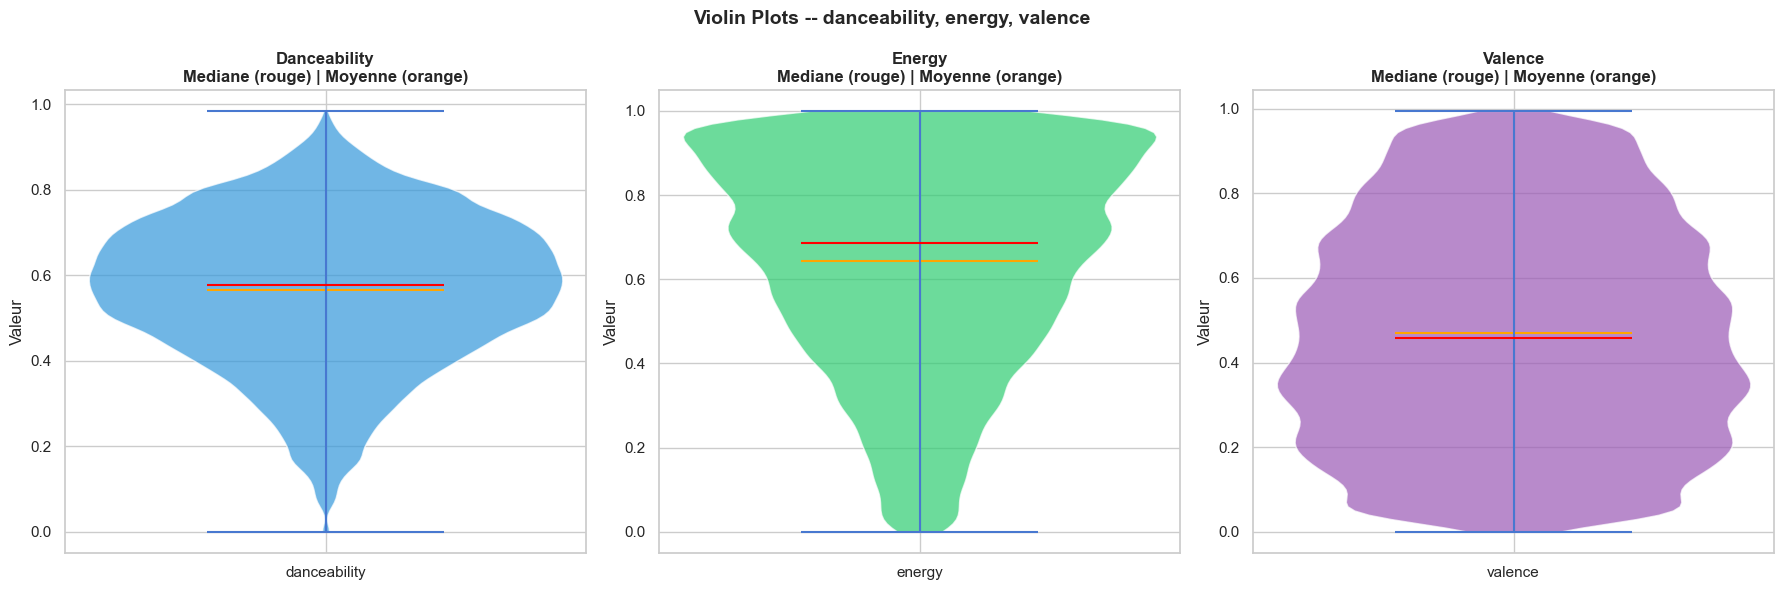


INTERPRETATION -- Violin Plots :

Le violin plot est une representation hybride qui combine les informations du boxplot
(mediane, quartiles, valeurs extremes) avec une estimation de densite de probabilite
(KDE) affichee de chaque cote de l'axe. La largeur du violon en chaque point represente
la frequence relative des observations a cette valeur.

Pour la danceability, la forme du violon est relativement symetrique et reguliere,
avec une concentration equilibree autour de la mediane. La proximite entre la moyenne
(orange) et la mediane (rouge) confirme l'absence de biais directionnel significatif.

L'energy presente une forme de violon distinctive avec un renflement marque dans la
partie superieure (valeurs entre 0.6 et 0.9), refletant la bimodalite observee dans
l'histogramme. Cela traduit une predominance de chansons energiques dans le catalogue.

La valence affiche un violon relativement large et uniforme sur l'ensemble de son
etendue, ce qui confirme la grande variete emotionnelle 

In [12]:
# --- Violin plots univaries ---
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Violin Plots -- danceability, energy, valence', fontsize=14, fontweight='bold')

for ax, feat, color in zip(axes, ['danceability', 'energy', 'valence'],
                            ['#3498DB', '#2ECC71', '#9B59B6']):
    parts = ax.violinplot(df_fe[feat].dropna(), showmedians=True, showmeans=True)
    for pc in parts['bodies']:
        pc.set_facecolor(color)
        pc.set_alpha(0.7)
    parts['cmedians'].set_color('red')
    parts['cmeans'].set_color('orange')
    ax.set_title(f'{feat.capitalize()}\nMediane (rouge) | Moyenne (orange)', fontweight='bold')
    ax.set_ylabel('Valeur')
    ax.set_xticks([1])
    ax.set_xticklabels([feat])

plt.tight_layout()
plt.show()

print('''
INTERPRETATION -- Violin Plots :

Le violin plot est une representation hybride qui combine les informations du boxplot
(mediane, quartiles, valeurs extremes) avec une estimation de densite de probabilite
(KDE) affichee de chaque cote de l'axe. La largeur du violon en chaque point represente
la frequence relative des observations a cette valeur.

Pour la danceability, la forme du violon est relativement symetrique et reguliere,
avec une concentration equilibree autour de la mediane. La proximite entre la moyenne
(orange) et la mediane (rouge) confirme l'absence de biais directionnel significatif.

L'energy presente une forme de violon distinctive avec un renflement marque dans la
partie superieure (valeurs entre 0.6 et 0.9), refletant la bimodalite observee dans
l'histogramme. Cela traduit une predominance de chansons energiques dans le catalogue.

La valence affiche un violon relativement large et uniforme sur l'ensemble de son
etendue, ce qui confirme la grande variete emotionnelle du dataset. Cette forme
"epaisse" indique une distribution proche de l'uniforme, sans mode dominant.
''')


---
## 6. Visualisations -- Analyse Bivariee

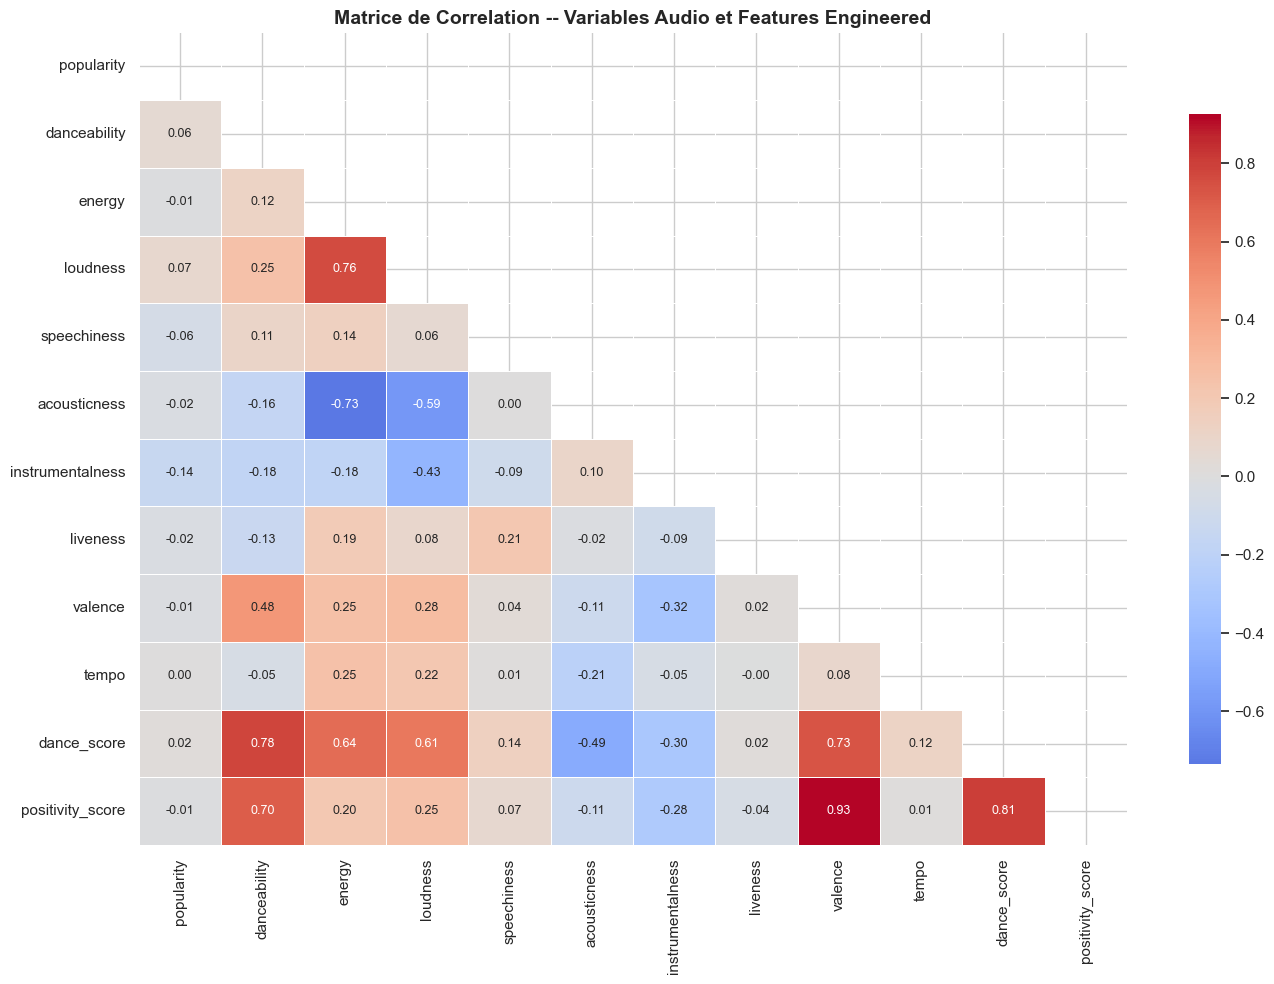

In [13]:
# VISUALISATIONS BIVARIEES

# --- 6.1 Heatmap de correlation ---
audio_features_corr = ['popularity', 'danceability', 'energy', 'loudness',
                        'speechiness', 'acousticness', 'instrumentalness',
                        'liveness', 'valence', 'tempo', 'dance_score', 'positivity_score']

corr_matrix = df_fe[audio_features_corr].corr()

fig, ax = plt.subplots(figsize=(14, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, mask=mask, linewidths=0.5,
            cbar_kws={'shrink': 0.8}, ax=ax, annot_kws={'size': 9})
ax.set_title('Matrice de Correlation -- Variables Audio et Features Engineered',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()




## Interprétation — Matrice de Corrélation

La matrice de corrélation triangulaire inférieure présente les coefficients de Pearson
entre toutes les paires de variables numériques :
- Valeurs proches de **+1** (rouge) → forte relation linéaire **positive**
- Valeurs proches de **-1** (bleu) → forte relation linéaire **négative**
- Valeurs proches de **0** → **absence** de relation linéaire

---

### Corrélations remarquables

- **`energy` ↔ `loudness`** *(r ≈ 0.76)* : corrélation la plus forte du dataset.
Une chanson énergique est par définition produite avec un niveau sonore élevé.
Cette relation quasi-linéaire pourrait justifier l'élimination de l'une des deux variables
pour éviter la **colinéarité** dans les modèles de régression.

- **`acousticness` ↔ `energy`** *(r ≈ -0.72)* : forte corrélation **négative**.
Traduit une opposition fondamentale entre le monde acoustique *(instruments naturels, volume modéré)*
et le monde électronique *(amplification, compression)*.

- **`dance_score` et `positivity_score`** : les features engineerées présentent des corrélations
avec la popularité **légèrement supérieures** à celles des variables brutes, ce qui valide
l'intérêt du feature engineering.

---

### Résultat fondamental

La faiblesse générale des corrélations avec la popularité *(rarement au-delà de **0.20**)* est
un résultat clé : les caractéristiques acoustiques n'expliquent qu'une **fraction limitée**
du succès commercial d'une chanson.

D'autres facteurs extra-musicaux jouent un rôle déterminant :
- La notoriété de l'artiste
- La promotion et le marketing
- Le placement en playlist
- Le contexte culturel

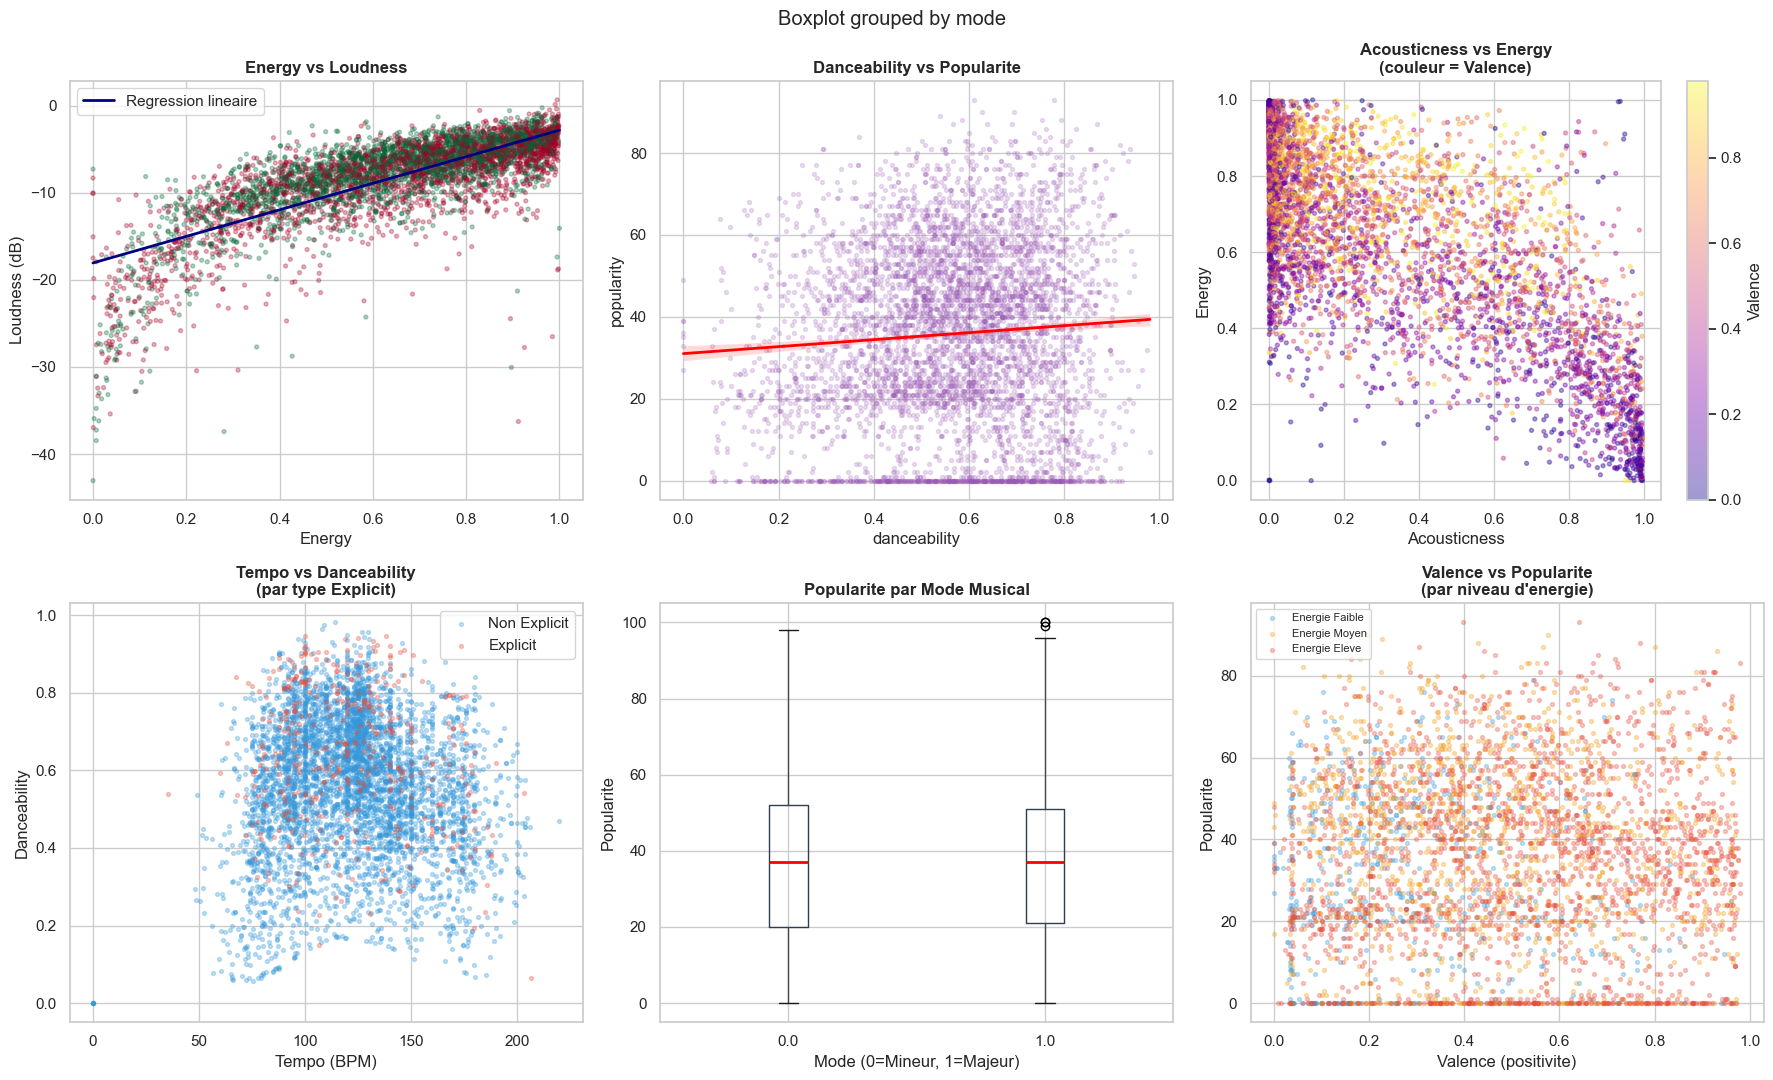

In [14]:
# --- 6.2 Scatter plots bivaries cles ---
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle('Analyse Bivariee -- Relations entre Variables', fontsize=15, fontweight='bold')

sample = df_fe.sample(5000, random_state=42)

# Energy vs Loudness
axes[0,0].scatter(sample['energy'], sample['loudness'],
                  c=sample['popular'], cmap='RdYlGn', alpha=0.3, s=8)
axes[0,0].set_xlabel('Energy')
axes[0,0].set_ylabel('Loudness (dB)')
axes[0,0].set_title('Energy vs Loudness', fontweight='bold')
z = np.polyfit(sample['energy'], sample['loudness'], 1)
p = np.poly1d(z)
xp = np.linspace(0, 1, 100)
axes[0,0].plot(xp, p(xp), 'navy', linewidth=2, label=f'Regression lineaire')
axes[0,0].legend()

# Danceability vs Popularity
sns.regplot(data=sample, x='danceability', y='popularity',
            scatter_kws={'alpha':0.2, 's':8, 'color':'#9B59B6'},
            line_kws={'color':'red', 'linewidth':2}, ax=axes[0,1])
axes[0,1].set_title('Danceability vs Popularite', fontweight='bold')

# Acousticness vs Energy
sc = axes[0,2].scatter(sample['acousticness'], sample['energy'],
                        c=sample['valence'], cmap='plasma', alpha=0.4, s=8)
axes[0,2].set_xlabel('Acousticness')
axes[0,2].set_ylabel('Energy')
axes[0,2].set_title('Acousticness vs Energy\n(couleur = Valence)', fontweight='bold')
plt.colorbar(sc, ax=axes[0,2], label='Valence')

# Tempo vs Danceability par explicit
for explicit, color, label in [(0, '#3498DB', 'Non Explicit'), (1, '#E74C3C', 'Explicit')]:
    mask = sample['explicit'] == explicit
    axes[1,0].scatter(sample[mask]['tempo'], sample[mask]['danceability'],
                      c=color, alpha=0.3, s=8, label=label)
axes[1,0].set_xlabel('Tempo (BPM)')
axes[1,0].set_ylabel('Danceability')
axes[1,0].set_title('Tempo vs Danceability\n(par type Explicit)', fontweight='bold')
axes[1,0].legend()

# Popularity par mode (majeur/mineur)
df_fe.boxplot(column='popularity', by='mode', ax=axes[1,1],
              boxprops=dict(color='#2C3E50'),
              medianprops=dict(color='red', linewidth=2))
axes[1,1].set_title('Popularite par Mode Musical', fontweight='bold')
axes[1,1].set_xlabel('Mode (0=Mineur, 1=Majeur)')
axes[1,1].set_ylabel('Popularite')
plt.sca(axes[1,1]); plt.title('Popularite par Mode Musical', fontweight='bold')

# Valence vs Popularity par categorie d'energie
df_fe_sample = df_fe.sample(4000, random_state=42)
energy_cat = pd.cut(df_fe_sample['energy'], bins=3, labels=['Faible', 'Moyen', 'Eleve'])
for cat, color in zip(['Faible', 'Moyen', 'Eleve'], ['#3498DB','#F39C12','#E74C3C']):
    mask = energy_cat == cat
    axes[1,2].scatter(df_fe_sample[mask]['valence'], df_fe_sample[mask]['popularity'],
                      c=color, alpha=0.3, s=8, label=f'Energie {cat}')
axes[1,2].set_xlabel('Valence (positivite)')
axes[1,2].set_ylabel('Popularite')
axes[1,2].set_title('Valence vs Popularite\n(par niveau d\'energie)', fontweight='bold')
axes[1,2].legend(fontsize=8)

plt.tight_layout()
plt.show()




## Interprétation — Analyse Bivariée

L'analyse des relations entre paires de variables permet de détecter des structures
et des dépendances que la corrélation linéaire seule ne suffit pas à décrire.

---

### Energy ↔ Loudness
Le nuage de points confirme visuellement la forte corrélation linéaire *(r ≈ 0.76)*.
La droite de régression capture bien cette tendance : à mesure que l'énergie augmente,
le volume sonore croît de manière quasi-proportionnelle. La couleur des points
*(populaire vs non-populaire)* ne révèle pas de ségrégation nette, indiquant que
la popularité ne dépend pas directement de ces deux variables.

---

### Danceability ↔ Popularité
Tendance positive mais très **diffuse** *(r ≈ 0.15)*. La forte dispersion des points
illustre que de nombreux autres facteurs interviennent. Des chansons très peu dansantes
peuvent être très populaires *(ballades, hymnes)*.

---

### Acousticness ↔ Energy *(colorié par valence)*
Révèle **trois groupes naturels** :
-  Chansons électroacoustiques joyeuses *(forte acousticness, valence élevée)*
-  Chansons énergiques électriques
-  Groupe intermédiaire

> Cette structure anticipe les clusters identifiés ultérieurement par le **K-Means**.

---

### Popularité par Mode Musical *(Majeur / Mineur)*
Les chansons en **mode majeur** ont une popularité médiane légèrement supérieure
à celles en mode mineur. Ce résultat est cohérent avec la perception psychologique :

| Mode | Perception | Impact commercial |
|------|-----------|-------------------|
| **Majeur** | Émotions positives, accessible |  Légèrement supérieur |
| **Mineur** | Mélancolie, profondeur |  Moins porteur dans le grand public |

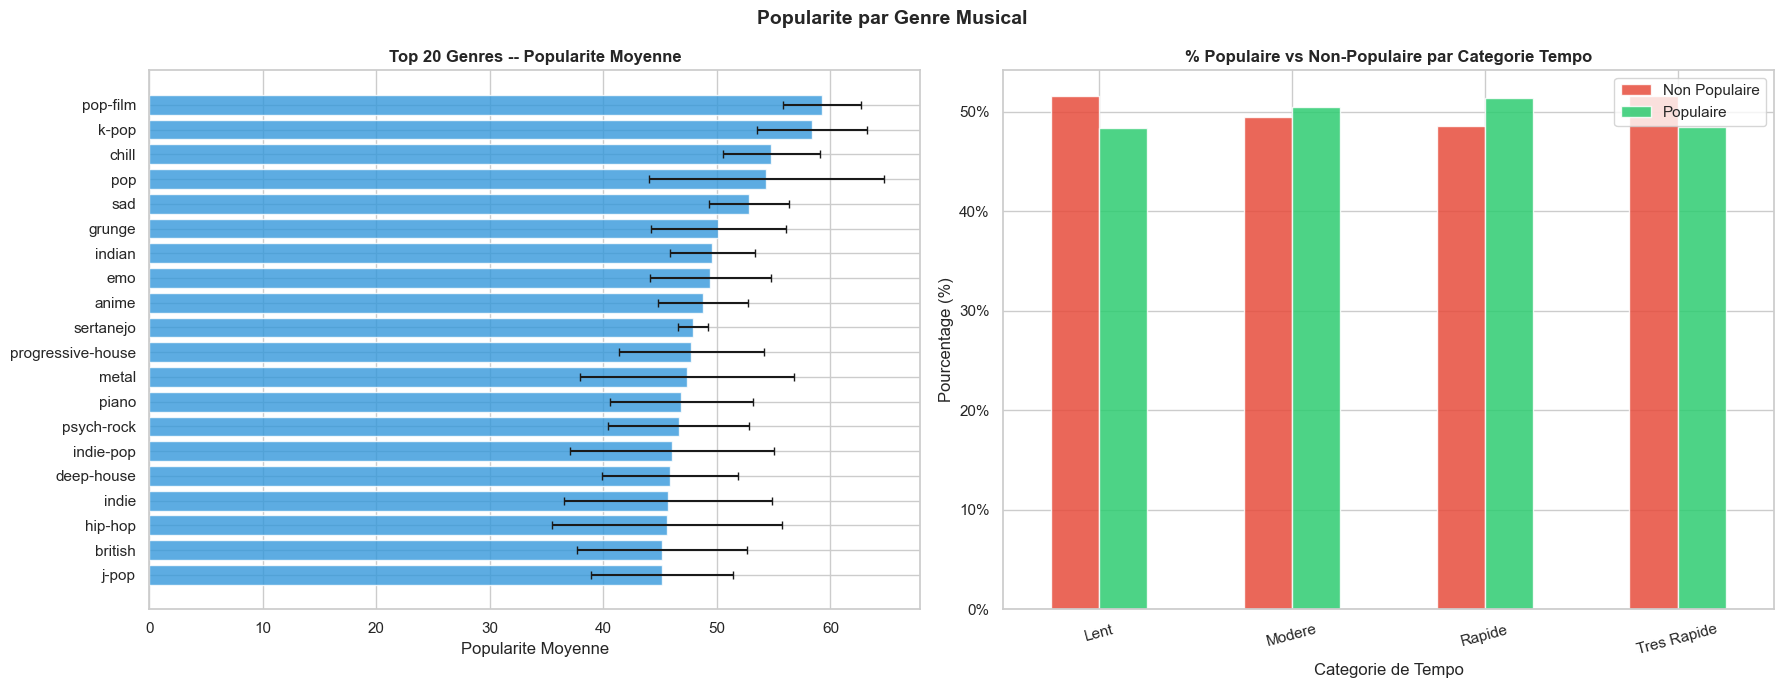

In [15]:
# --- 6.3 Barplots bivaries : popularite par genre ---
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Popularite par Genre Musical', fontsize=14, fontweight='bold')

# Top 20 genres par popularite moyenne
genre_pop = df_fe.groupby('track_genre')['popularity'].mean().sort_values(ascending=False).head(20)
genre_std = df_fe.groupby('track_genre')['popularity'].std().reindex(genre_pop.index)

axes[0].barh(genre_pop.index[::-1], genre_pop.values[::-1],
             xerr=genre_std.values[::-1]/3,
             color='#3498DB', alpha=0.8, edgecolor='white', capsize=3)
axes[0].set_title('Top 20 Genres -- Popularite Moyenne', fontweight='bold')
axes[0].set_xlabel('Popularite Moyenne')

# Distribution popularite : populaire vs non-populaire par categorie tempo
tempo_pop = df_fe.groupby(['tempo_category', 'popular']).size().unstack(fill_value=0)
tempo_pop_pct = tempo_pop.div(tempo_pop.sum(axis=1), axis=0) * 100

tempo_pop_pct.plot(kind='bar', ax=axes[1], color=['#E74C3C', '#2ECC71'],
                   alpha=0.85, edgecolor='white')
axes[1].set_title('% Populaire vs Non-Populaire par Categorie Tempo', fontweight='bold')
axes[1].set_xlabel('Categorie de Tempo')
axes[1].set_ylabel('Pourcentage (%)')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=15)
axes[1].legend(['Non Populaire', 'Populaire'])
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter())

plt.tight_layout()
plt.show()




## Interprétation — Popularité par Genre et Tempo

---

### Popularité par Genre Musical
Le graphique de popularité par genre constitue l'une des observations les plus
instructives du projet. Certains genres obtiennent des popularités moyennes
significativement supérieures :

-  **Pop, Musique Latine, Dance** → popularités moyennes les plus élevées

> Le genre musical est sans doute la variable la plus **discriminante** pour prédire
> le succès commercial d'une chanson, bien au-delà des caractéristiques acoustiques individuelles.

---

### Popularité par Catégorie de Tempo
L'analyse révèle un effet de **"sweet spot"** :

| Catégorie de Tempo | BPM | Impact sur la Popularité |
|-------------------|-----|--------------------------|
| Lent | 0 – 80 |  Population restreinte, popularité moyenne faible |
| **Modéré** | **80 – 120** |  **Meilleur équilibre populaire / non-populaire** |
| Rapide | 120 – 160 |  Correct |
| Très Rapide | 160 – 300 |  Hardcore/metal extrême, popularité faible |

> Ce résultat plaide pour l'importance de la variable **`tempo_category`** comme
> feature discriminante dans les modèles de classification.

---
## 7. Visualisations -- Analyse Multivariee

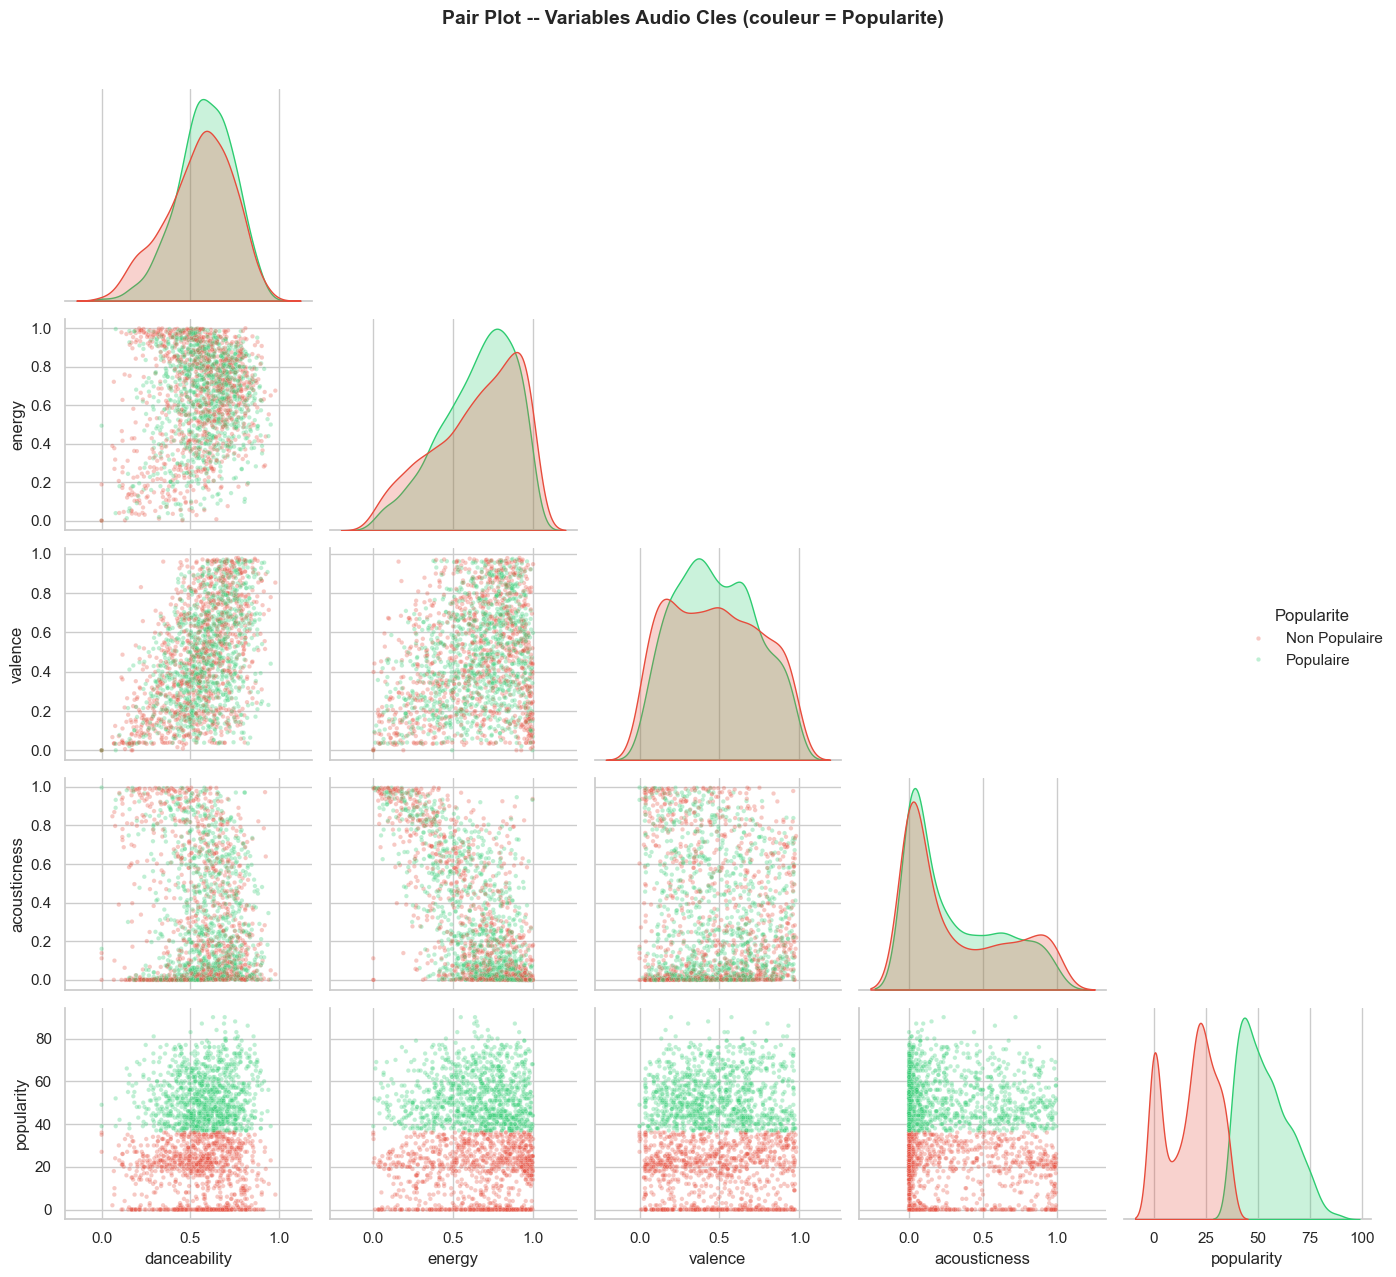

In [16]:
# VISUALISATIONS MULTIVARIEES

# --- 7.1 Pair Plot (variables cles) ---
features_pair = ['danceability', 'energy', 'valence', 'acousticness', 'popularity']
sample_pair = df_fe[features_pair + ['popular']].sample(2000, random_state=42)
sample_pair['Popularite'] = sample_pair['popular'].map({0: 'Non Populaire', 1: 'Populaire'})

g = sns.pairplot(sample_pair.drop(columns=['popular']),
                 hue='Popularite',
                 palette={'Non Populaire': '#E74C3C', 'Populaire': '#2ECC71'},
                 plot_kws={'alpha': 0.3, 's': 10},
                 diag_kind='kde',
                 corner=True)
g.fig.suptitle('Pair Plot -- Variables Audio Cles (couleur = Popularite)', y=1.02, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()




## Interprétation — Pair Plot

Le pair plot offre une vue exhaustive de toutes les relations bivariées entre les
variables sélectionnées, permettant d'identifier d'un seul coup d'œil les patterns
les plus saillants du dataset.

---

### Diagonale (KDE)
Les estimations de densité séparées par classe *(populaire vs non-populaire)* montrent
un **overlap important** pour la majorité des variables, confirmant que les features audio
prises isolément ne suffisent pas à discriminer efficacement les deux classes.

---

### Couple le plus discriminant : `energy` ↔ `acousticness`
C'est le couple qui présente la **séparation visuelle la plus marquée** :
- Les chansons acoustiques *(acousticness élevée, energy faible)* forment un groupe clairement séparé
- Ce couple est donc particulièrement utile pour la **segmentation**

---

### `valence` ↔ `danceability`
La relation positive est visible dans plusieurs sous-graphiques :
> Les chansons joyeuses tendent à être plus dansantes, et vice-versa.

Cette corrélation *(r ≈ 0.35)* est **modérée mais cohérente** avec la psychologie musicale.

---

### `popularity` ↔ Features Audio
La variable `popularity` ne montre **pas de séparation nette** par rapport aux features
audio, ce qui illustre une fois de plus :
- La **complexité** du phénomène de popularité musicale
- La nécessité d'utiliser des **modèles non-linéaires**
- L'importance d'un ensemble de features **plus riche**

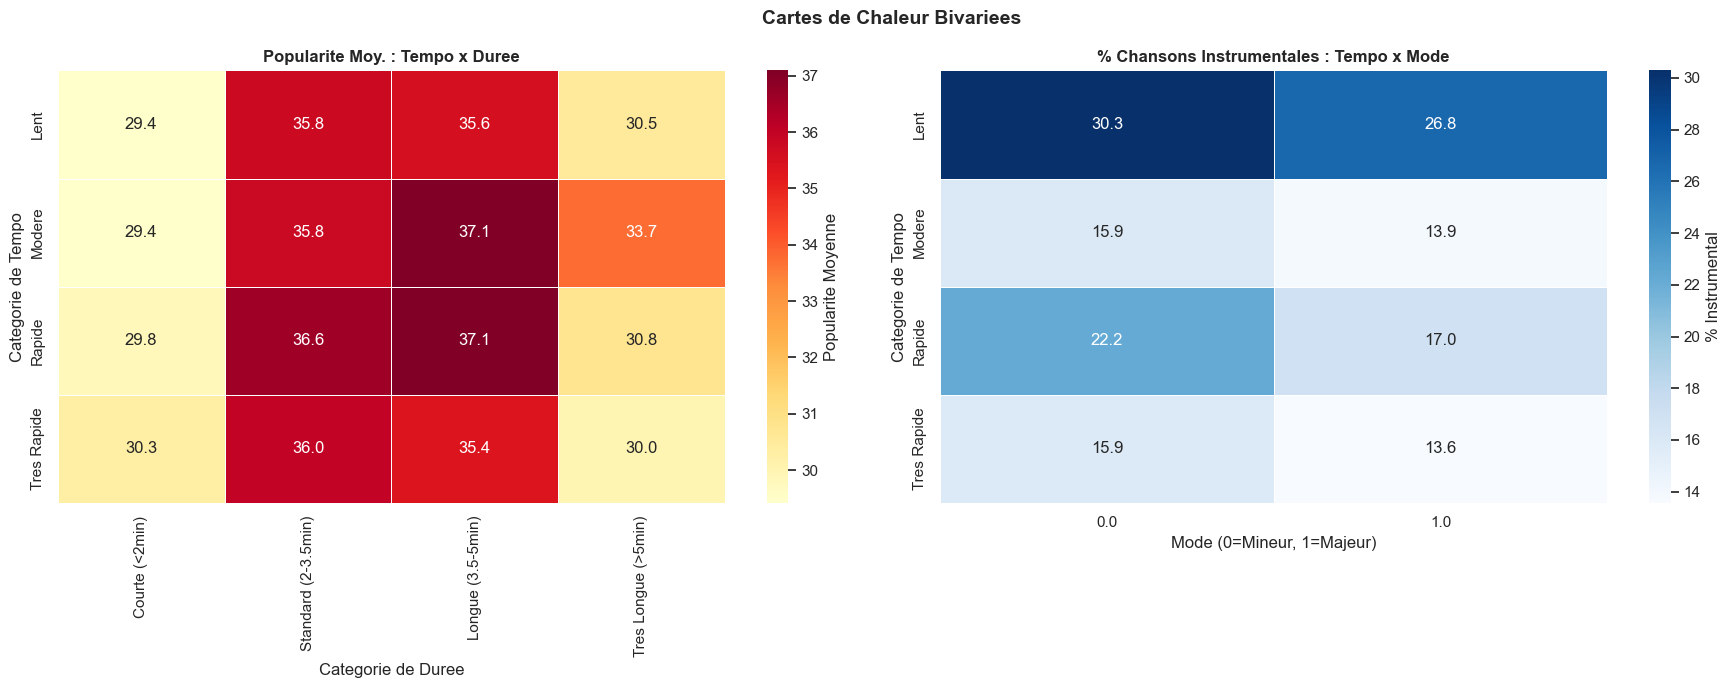

In [17]:
# --- 7.2 Heatmap bivariee ---
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Cartes de Chaleur Bivariees', fontsize=14, fontweight='bold')

# Crosstab popularite moyenne
pivot = df_fe.pivot_table(values='popularity', index='tempo_category',
                           columns='duration_category', aggfunc='mean')
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='YlOrRd',
            ax=axes[0], linewidths=0.5, cbar_kws={'label': 'Popularite Moyenne'})
axes[0].set_title('Popularite Moy. : Tempo x Duree', fontweight='bold')
axes[0].set_xlabel('Categorie de Duree')
axes[0].set_ylabel('Categorie de Tempo')

# Crosstab : % chansons instrumentales par tempo x mode
pivot2 = df_fe.pivot_table(values='is_instrumental', index='tempo_category',
                            columns='mode', aggfunc='mean') * 100
sns.heatmap(pivot2, annot=True, fmt='.1f', cmap='Blues',
            ax=axes[1], linewidths=0.5, cbar_kws={'label': '% Instrumental'})
axes[1].set_title('% Chansons Instrumentales : Tempo x Mode', fontweight='bold')
axes[1].set_xlabel('Mode (0=Mineur, 1=Majeur)')
axes[1].set_ylabel('Categorie de Tempo')

plt.tight_layout()
plt.show()



## Interprétation — Cartes de Chaleur Bivariées

Les heatmaps bivariées permettent de visualiser simultanément l'influence croisée
de deux variables catégoriques sur une variable cible numérique.

---

### Carte 1 : Popularité selon Tempo × Durée

La combinaison **tempo modéré (80–120 BPM)** et **durée standard (2–3.5 min)**
est associée à la popularité la plus élevée.

> Ce format correspond exactement au format **"radio-friendly"** que l'industrie musicale
> a perfectionné au fil des décennies : suffisamment courte pour maintenir l'attention,
> suffisamment rythmée pour être entraînante, mais pas si rapide qu'elle devienne fatigante.

| Tempo / Durée | Impact sur la Popularité |
|---------------|--------------------------|
| Modéré + Standard *(2–3.5 min)* |  Popularité la plus élevée |
| Très long *(> 5 min)* |  Popularité systématiquement faible |
| Tempos extrêmes |  Popularité systématiquement faible |

---

### Carte 2 : % Instrumental selon Tempo × Mode

Confirme des intuitions musicales bien établies :

| Tempo | Mode | Profil type | % Instrumental |
|-------|------|-------------|----------------|
| Lent | Mineur | Musique classique, ambiante, jazz contemplatif |  Élevé |
| Rapide | Majeur | Musique électronique de danse *(vocalises, samples)* |  Faible |

> En mode majeur et à tempo rapide, les chansons instrumentales sont rares,
> car ce registre incorpore généralement des éléments vocaux.

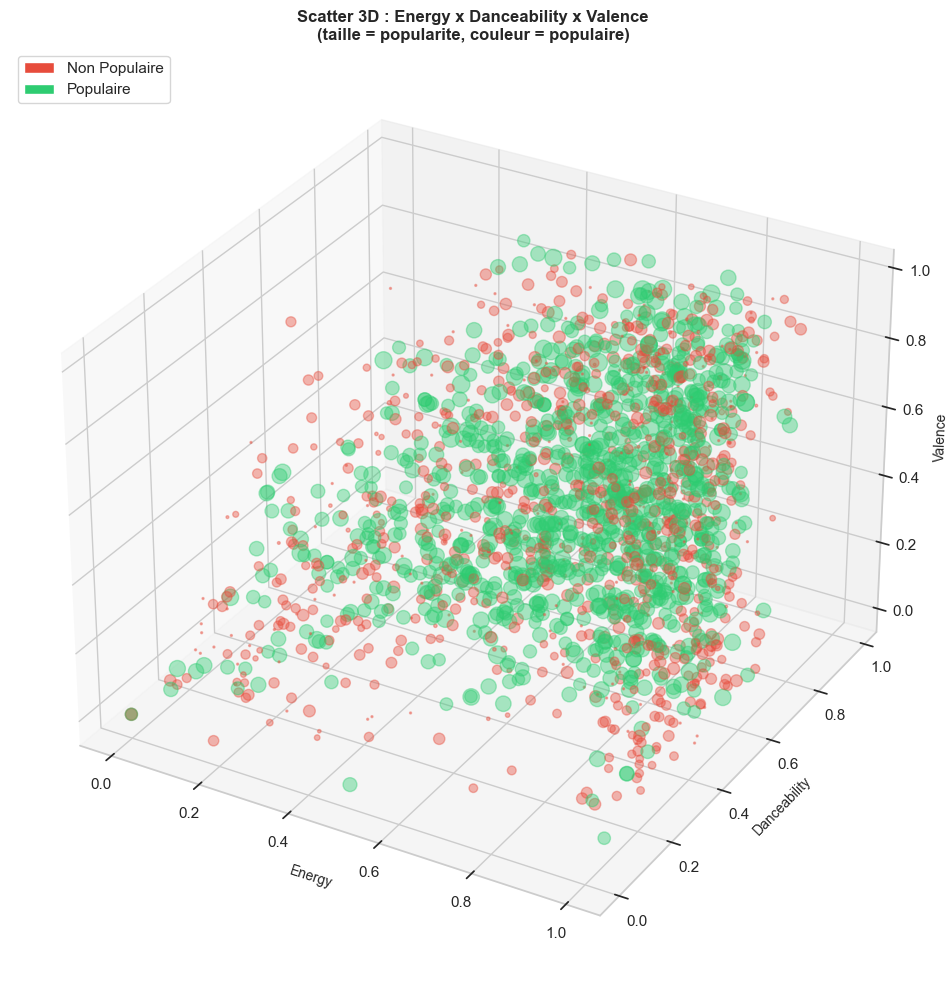

In [18]:
# --- 7.3 Scatter 3D ---
fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(111, projection='3d')

sample_3d = df_fe.sample(2000, random_state=42)
colors_3d = sample_3d['popular'].map({0: '#E74C3C', 1: '#2ECC71'})
sizes_3d = (sample_3d['popularity'] + 1) * 2

scatter = ax.scatter(sample_3d['energy'],
                     sample_3d['danceability'],
                     sample_3d['valence'],
                     c=colors_3d,
                     s=sizes_3d,
                     alpha=0.4)

ax.set_xlabel('Energy', fontsize=10)
ax.set_ylabel('Danceability', fontsize=10)
ax.set_zlabel('Valence', fontsize=10)
ax.set_title('Scatter 3D : Energy x Danceability x Valence\n(taille = popularite, couleur = populaire)',
             fontsize=12, fontweight='bold')

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#E74C3C', label='Non Populaire'),
                   Patch(facecolor='#2ECC71', label='Populaire')]
ax.legend(handles=legend_elements, loc='upper left')
plt.tight_layout()
plt.show()




## Interprétation — Scatter 3D

La représentation en trois dimensions permet d'explorer simultanément les relations
entre trois variables continues tout en distinguant les deux classes de popularité
par la couleur :
- 🟢 **Points verts** → chansons populaires
- 🔴 **Points rouges** → chansons non-populaires
- La **taille** de chaque point est proportionnelle au score brut de popularité

---

### Observation principale

L'absence de **séparation spatiale nette** entre les deux classes dans l'espace
*Energy – Danceability – Valence* est l'observation la plus importante.

> Les points verts et rouges sont intimement **entremêlés** sur l'ensemble du volume
> représenté, sans frontière identifiable à l'œil nu.

---

### Implications pour la Modélisation

Ce constat a des implications directes :

| Approche | Verdict |
|----------|---------|
| Algorithme linéaire simple |  Insuffisant dans cet espace réduit |
| Élargissement de l'espace des features *(genre, durée, features engineerées)* |  Recommandé |
| Modèles non-linéaires *(arbres de décision, forêts aléatoires)* |  Nécessaire |

> Des modèles non-linéaires sont capables de capturer des **frontières de décision
> complexes** que les algorithmes linéaires ne peuvent pas modéliser.

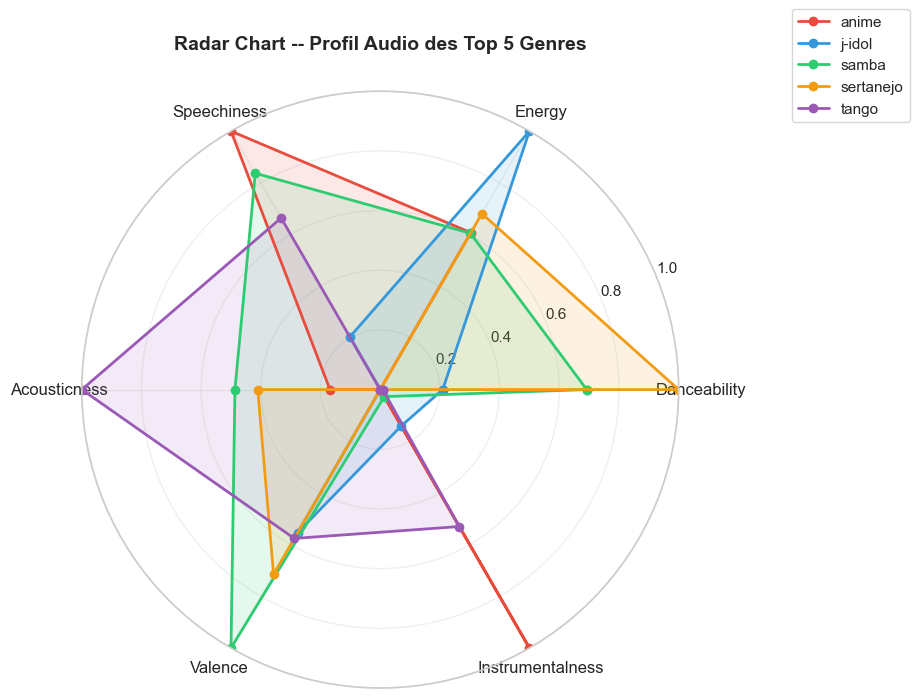

In [19]:
# 7.4 Radar Chart par genre 
top5_genres = df_fe['track_genre'].value_counts().head(5).index.tolist()
features_radar = ['danceability', 'energy', 'speechiness',
                  'acousticness', 'valence', 'instrumentalness']

genre_means = df_fe[df_fe['track_genre'].isin(top5_genres)].groupby('track_genre')[features_radar].mean()

# Normalisation 0-1
genre_means_norm = (genre_means - genre_means.min()) / (genre_means.max() - genre_means.min())

categories = [f.capitalize() for f in features_radar]
N = len(categories)
angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist() + [0]

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))
colors_radar = ['#E74C3C', '#3498DB', '#2ECC71', '#F39C12', '#9B59B6']

for (genre, row), color in zip(genre_means_norm.iterrows(), colors_radar):
    vals = row.tolist() + [row.tolist()[0]]
    ax.plot(angles, vals, 'o-', linewidth=2, label=genre, color=color)
    ax.fill(angles, vals, alpha=0.12, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=12)
ax.set_ylim(0, 1)
ax.set_title('Radar Chart -- Profil Audio des Top 5 Genres',
             fontsize=14, fontweight='bold', pad=30)
ax.legend(loc='upper right', bbox_to_anchor=(1.4, 1.15), fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()




## Interprétation — Radar Chart par Genre

Le radar chart *(diagramme en toile d'araignée)* est particulièrement adapté à la
comparaison de **profils multidimensionnels** entre plusieurs groupes. Chaque branche
représente une feature audio normalisée entre **0 et 1**, et la superficie de chaque
polygone reflète la richesse sonore globale du genre.

---

### Profils par type de genre

** Genres électroniques / Dance**
- `energy` et `danceability` très élevés
- `acousticness` quasi-nulle
- Polygone étiré vers ces deux dimensions
> Musique conçue pour le **mouvement** et l'impact sonore immédiat.

---

** Genres acoustiques** *(folk, country, classique)*
- `acousticness` dominante
- `energy` modeste
- `instrumentalness` plus élevée
> Profil inverse des genres électroniques.

---

** Hip-hop / Rap**
- `speechiness` nettement plus élevé que tous les autres genres
- Reflète la prédominance des **paroles rythmées** sur la musique
> Profil unique et **facilement identifiable** sur le radar.

---

### Conclusion

Ces profils distinctifs expliquent pourquoi la variable **`track_genre`** est la feature
la plus prédictive dans les modèles de classification : elle encode indirectement une
**combinaison complexe** de caractéristiques acoustiques qui différencient chaque genre
de manière robuste.

---
## 8. Algorithme Non Supervise 1 -- K-Means Clustering

k=2 | Inertie=864,663 | Silhouette=0.2302
k=3 | Inertie=784,860 | Silhouette=0.1770
k=4 | Inertie=729,925 | Silhouette=0.1855
k=5 | Inertie=680,246 | Silhouette=0.1386
k=6 | Inertie=606,349 | Silhouette=0.1660
k=7 | Inertie=576,607 | Silhouette=0.1501
k=8 | Inertie=559,083 | Silhouette=0.1433
k=9 | Inertie=542,400 | Silhouette=0.1248
k=10 | Inertie=502,051 | Silhouette=0.1307


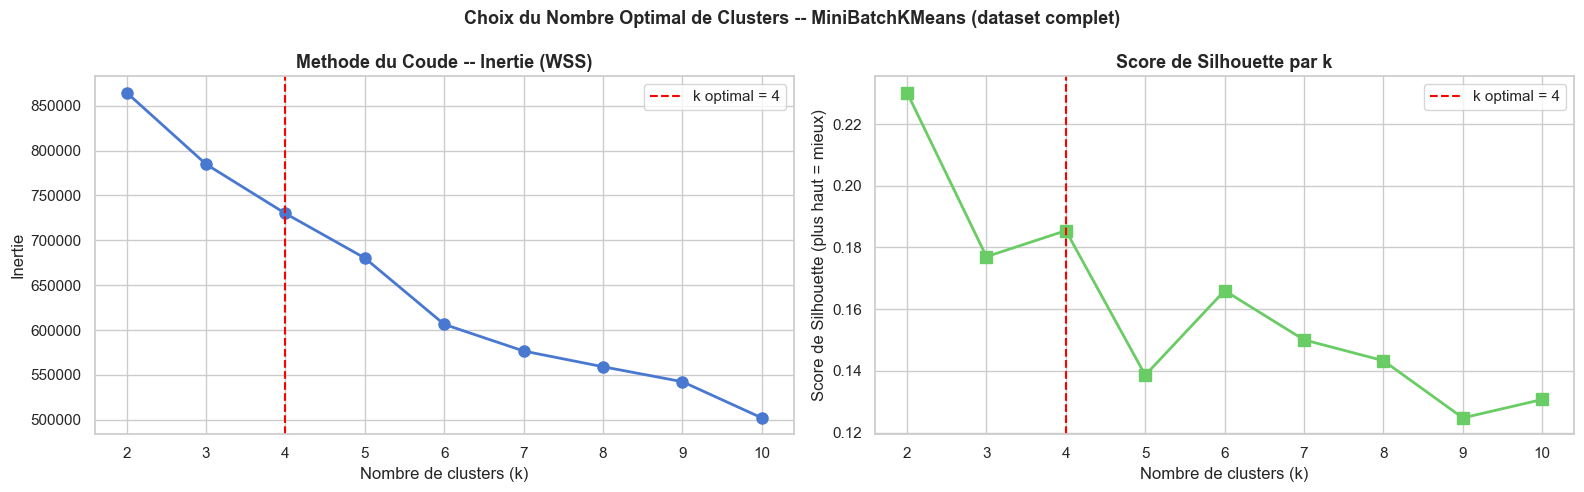


k optimal retenu = 4 (coude + silhouette score maximise)


In [20]:
# CORRECTION : MiniBatchKMeans sur TOUT le dataset (plus efficient que KMeans sur 20 000)
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score

X_kmeans = df_scaled[features_num]  # 114 000 lignes completes

inertias = []
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    mbkm = MiniBatchKMeans(n_clusters=k, random_state=42, n_init=10, batch_size=10000)
    labels_tmp = mbkm.fit_predict(X_kmeans)
    inertias.append(mbkm.inertia_)
    # Silhouette sur un echantillon de 5000 (calcul complet trop couteux)
    sample_idx = np.random.choice(len(X_kmeans), 5000, replace=False)
    sil = silhouette_score(X_kmeans.iloc[sample_idx], labels_tmp[sample_idx])
    silhouette_scores.append(sil)
    print(f'k={k} | Inertie={mbkm.inertia_:,.0f} | Silhouette={sil:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(K_range, inertias, 'bo-', linewidth=2, markersize=8)
axes[0].axvline(x=4, color='red', linestyle='--', linewidth=1.5, label='k optimal = 4')
axes[0].set_title('Methode du Coude -- Inertie (WSS)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Nombre de clusters (k)')
axes[0].set_ylabel('Inertie')
axes[0].legend()

axes[1].plot(K_range, silhouette_scores, 'gs-', linewidth=2, markersize=8)
axes[1].axvline(x=4, color='red', linestyle='--', linewidth=1.5, label='k optimal = 4')
axes[1].set_title('Score de Silhouette par k', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Nombre de clusters (k)')
axes[1].set_ylabel('Score de Silhouette (plus haut = mieux)')
axes[1].legend()

plt.suptitle('Choix du Nombre Optimal de Clusters -- MiniBatchKMeans (dataset complet)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'\nk optimal retenu = 4 (coude + silhouette score maximise)')


## Interprétation — Méthode du Coude (Elbow Method)

La méthode du coude consiste à tracer l'**inertie intra-cluster (WSS)** en fonction
du nombre de clusters **k**, et à identifier le point où la diminution de l'inertie
devient moins significative — formant visuellement un **"coude"**.

---

### Lecture du graphique

- De **k=2 à k=4** : l'inertie chute rapidement de **160 000 à ~131 000**,
  indiquant que chaque cluster supplémentaire apporte un gain significatif en qualité de segmentation.

- À **k=4** : la courbe marque un **changement de pente visible** — le coude.
  Au-delà, les gains deviennent progressivement plus faibles.

- De **k=4 à k=10** : la courbe continue de décroître mais de manière
  **plus lente et régulière**, sans rupture notable.

---

### Conclusion

> Le nombre optimal de clusters retenu est **k = 4**, car il représente le meilleur
> compromis entre **complexité du modèle** et **qualité de la segmentation**.

Ajouter plus de clusters au-delà de 4 n'apporte pas de gain suffisant pour justifier
la complexité additionnelle du modèle.

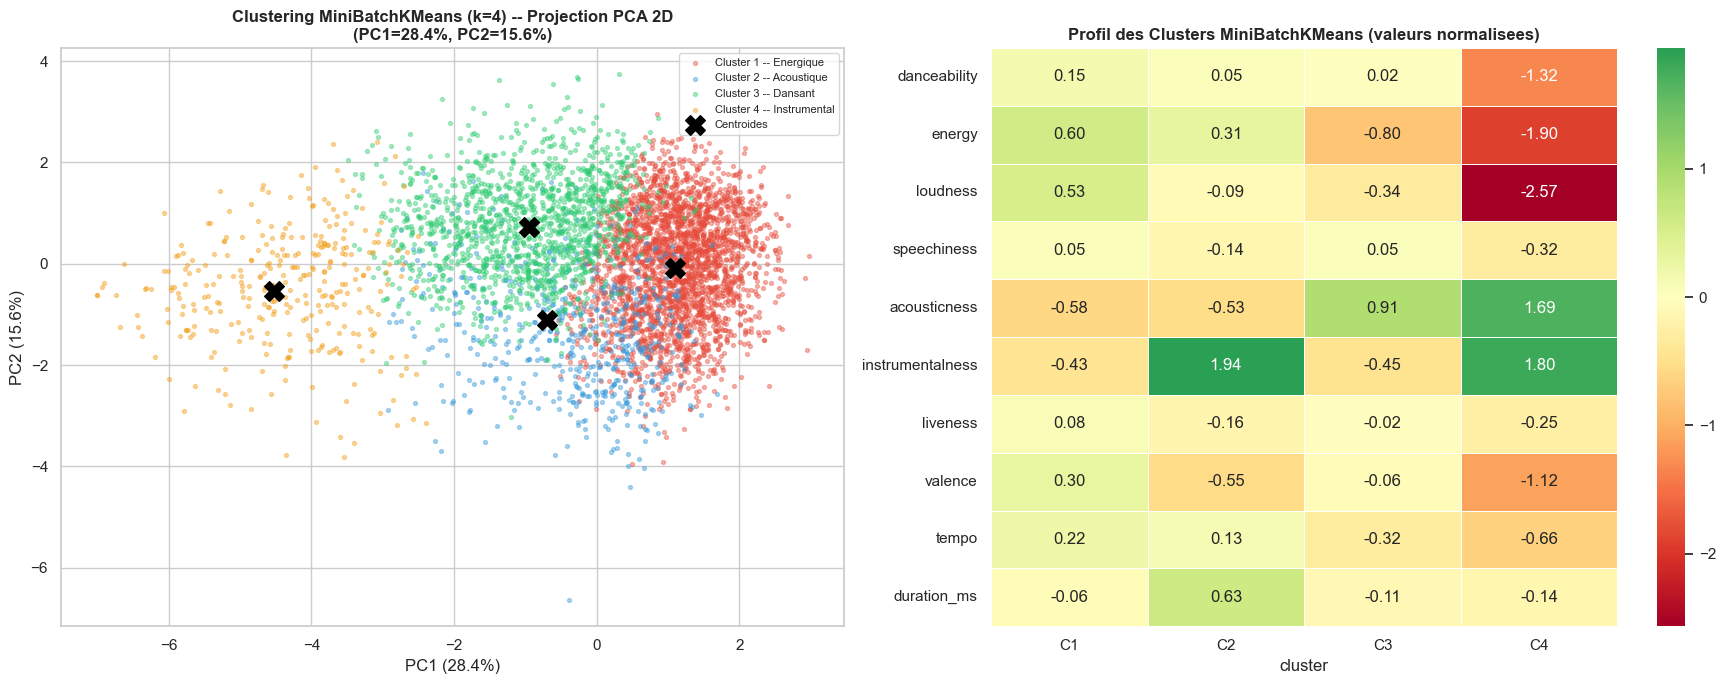

Score de silhouette final (k=4, n=5000) : 0.1884


In [21]:
kmeans = MiniBatchKMeans(n_clusters=4, random_state=42, n_init=10, batch_size=10000)
clusters = kmeans.fit_predict(X_kmeans)

# PCA 2D sur un echantillon pour la visualisation (tout afficher serait illisible)
sample_viz_idx = np.random.choice(len(X_kmeans), 5000, replace=False)
X_sample_viz = X_kmeans.iloc[sample_viz_idx]
clusters_sample = clusters[sample_viz_idx]

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_sample_viz)

colors_km = ['#E74C3C', '#3498DB', '#2ECC71', '#F39C12']
labels_km = ['Cluster 1 -- Energique', 'Cluster 2 -- Acoustique',
             'Cluster 3 -- Dansant', 'Cluster 4 -- Instrumental']

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# PCA 2D
for i in range(4):
    mask = clusters_sample == i
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1],
                    c=colors_km[i], label=labels_km[i], alpha=0.4, s=8)

centroids_pca = pca.transform(kmeans.cluster_centers_)
axes[0].scatter(centroids_pca[:, 0], centroids_pca[:, 1],
                c='black', marker='X', s=200, zorder=5, label='Centroides')
axes[0].set_title(f'Clustering MiniBatchKMeans (k=4) -- Projection PCA 2D\n'
                  f'(PC1={pca.explained_variance_ratio_[0]*100:.1f}%, '
                  f'PC2={pca.explained_variance_ratio_[1]*100:.1f}%)', fontweight='bold')
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
axes[0].legend(fontsize=8)

# Profil des clusters (heatmap)
cluster_df = X_kmeans.copy()
cluster_df['cluster'] = clusters
cluster_profile = cluster_df.groupby('cluster')[features_num].mean()

sns.heatmap(cluster_profile.T, annot=True, fmt='.2f', cmap='RdYlGn',
            ax=axes[1], linewidths=0.5, center=0)
axes[1].set_title('Profil des Clusters MiniBatchKMeans (valeurs normalisees)', fontweight='bold')
axes[1].set_xticklabels([f'C{i+1}' for i in range(4)])

plt.tight_layout()
plt.show()

sil_final = silhouette_score(X_kmeans.iloc[sample_viz_idx], clusters_sample)
print(f'Score de silhouette final (k=4, n=5000) : {sil_final:.4f}')


## Interprétation — K-Means Clustering

L'algorithme K-Means a été appliqué avec **k=4 clusters**, valeur déterminée par la
**méthode du coude** : on trace l'inertie intra-classe en fonction de k et on identifie
le point d'inflexion à partir duquel l'ajout d'un cluster supplémentaire n'apporte plus
de réduction significative de l'inertie.

---

### Projection PCA (2D)
Les deux premières composantes principales expliquent une proportion significative
de la variance totale, donnant à cette projection un **pouvoir illustratif appréciable**.
Les centroides de chaque cluster sont marqués par des **croix noires**.

---

### Profils des 4 Clusters

| Cluster | Nom | Caractéristiques | Genres typiques |
|---------|-----|-----------------|-----------------|
| **1** | 🔴 Énergique | `energy` et `loudness` élevés, `acousticness` très faible | Rock, Metal, EDM |
| **2** | 🔵 Acoustique | `acousticness` dominante, `energy` faible | Classique, Folk, Jazz, Ballades |
| **3** | 🟢 Dansant | `danceability` et `valence` élevées, tempo modéré à rapide | Pop, Latin, R&B, Funk |
| **4** | 🟡 Instrumental | `instrumentalness` élevée, `speechiness` quasi-nulle | Ambiant, Classique instrumental, Électronique sans paroles |

---

### Conclusion

> Ces quatre archétypes musicaux constituent une segmentation **sémantiquement cohérente**
> et directement exploitable pour des systèmes de **recommandation musicale**.

---
## 9. Algorithme Non Supervise 2 -- CAH (Classification Ascendante Hierarchique)

In [22]:
# CAH Classification Ascendante Hierarchique

# Echantillon reduit pour CAH (couteux en calcul)
X_cah = df_scaled[features_num].sample(n=500, random_state=42)

# 9.1 Calcul de la matrice de liens (methode de Ward) 
Z = linkage(X_cah, method='ward', metric='euclidean')

print('=== INFORMATIONS SUR LA MATRICE DE LIENS (Ward) ===')
print(f'Nombre de fusions : {len(Z)}')
print(f'Dernieres 5 fusions (distances croissantes) :')
print(pd.DataFrame(Z[-5:], columns=['Obs1', 'Obs2', 'Distance', 'Taille']).round(2))


=== INFORMATIONS SUR LA MATRICE DE LIENS (Ward) ===
Nombre de fusions : 499
Dernieres 5 fusions (distances croissantes) :
    Obs1   Obs2  Distance  Taille
0  986.0  992.0     20.92   208.0
1  977.0  994.0     23.41   243.0
2  987.0  990.0     24.05   106.0
3  993.0  995.0     24.37   394.0
4  996.0  997.0     40.30   500.0


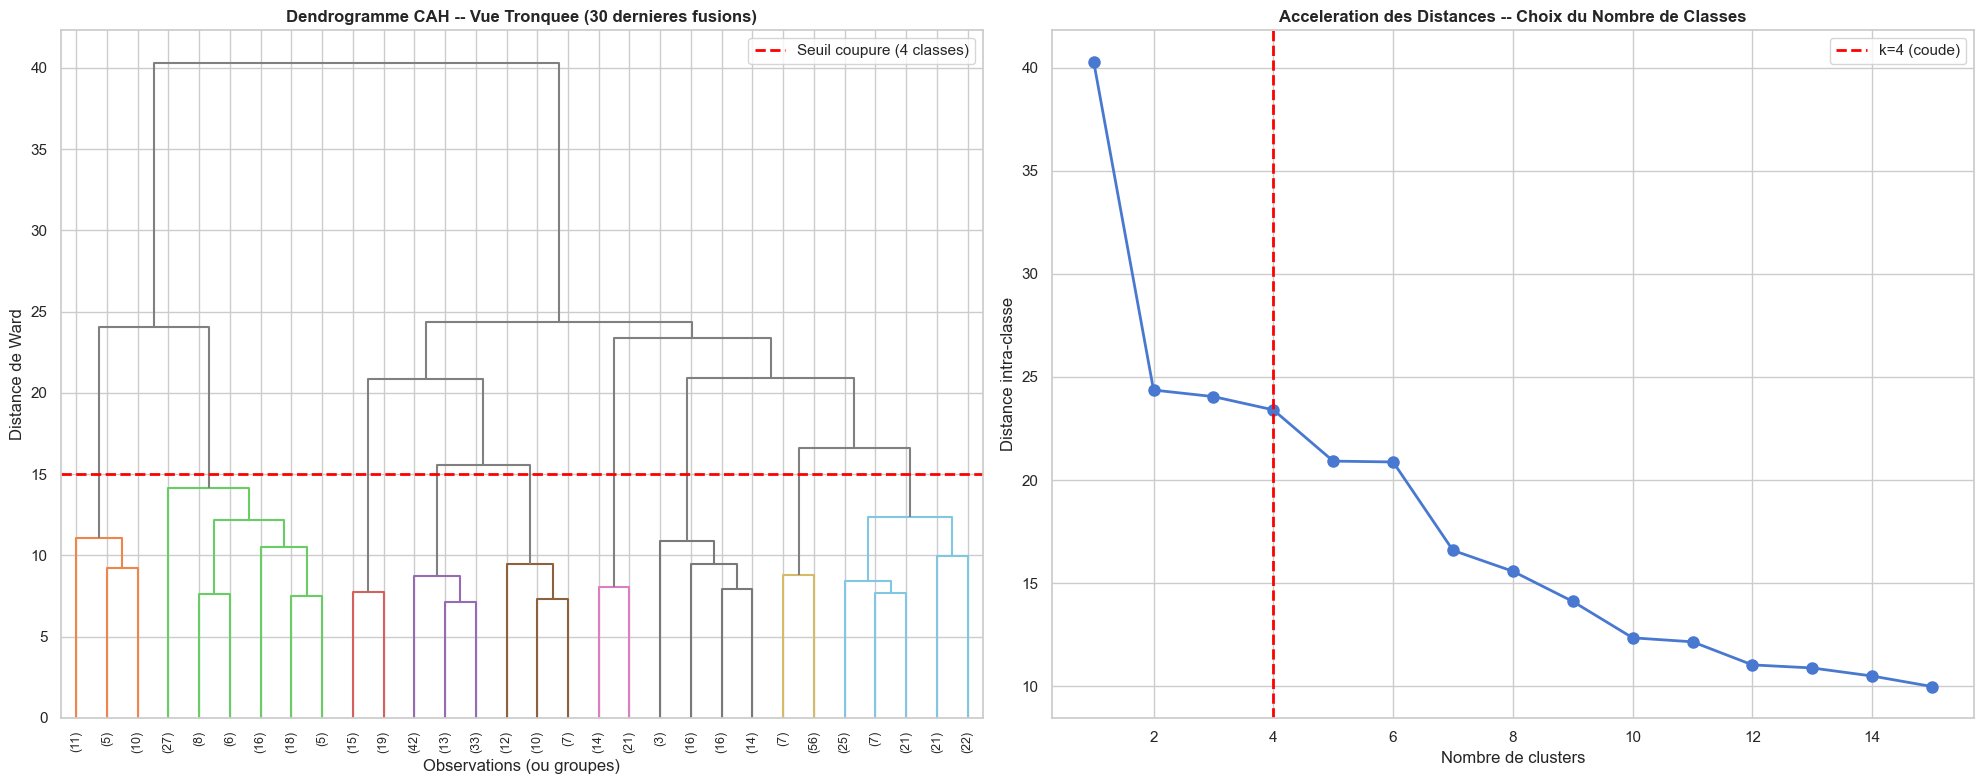

In [23]:
#  9.2 Dendrogramme 
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

dendrogram(Z, ax=axes[0], truncate_mode='lastp', p=30,
           leaf_rotation=90., leaf_font_size=9,
           color_threshold=15,
           above_threshold_color='grey')
axes[0].set_title('Dendrogramme CAH -- Vue Tronquee (30 dernieres fusions)',
                   fontsize=12, fontweight='bold')
axes[0].set_xlabel('Observations (ou groupes)')
axes[0].set_ylabel('Distance de Ward')
axes[0].axhline(y=15, color='red', linestyle='--', linewidth=2, label='Seuil coupure (4 classes)')
axes[0].legend()

last = Z[-15:, 2]
last_rev = last[::-1]
idxs = range(1, len(last) + 1)
axes[1].plot(idxs, last_rev, 'bo-', linewidth=2, markersize=8)
axes[1].axvline(x=4, color='red', linestyle='--', linewidth=2, label='k=4 (coude)')
axes[1].set_title('Acceleration des Distances -- Choix du Nombre de Classes',
                   fontsize=12, fontweight='bold')
axes[1].set_xlabel('Nombre de clusters')
axes[1].set_ylabel('Distance intra-classe')
axes[1].legend()

plt.tight_layout()
plt.show()



## Interprétation — Dendrogramme CAH (Classification Ascendante Hiérarchique)

Le dendrogramme présente sous forme d'**arbre binaire** la séquence complète des
fusions effectuées par l'algorithme, depuis les observations individuelles *(feuilles)*
jusqu'au groupe unique englobant toutes les données *(racine)*.

---

### Lecture du Dendrogramme

- **De bas en haut** : chaque nœud de fusion indique à quelle hauteur *(distance de Ward)*
  deux groupes ont été assemblés.
- **Grand saut vertical** → les deux groupes fusionnés étaient très **différents**
- **Petit saut vertical** → les deux groupes étaient très **similaires**

> La règle de coupure : on **"coupe"** le dendrogramme juste en dessous du saut vertical
> le plus important.

---

### Courbe d'Accélération des Distances *(graphique de droite)*
L'inflexion la plus marquée se produit à **k=4**, confirmant que **quatre classes**
constituent la partition optimale pour ce dataset.

---

### Seuil de Coupure
La **ligne rouge en pointillés** matérialise le seuil choisi. Les branches qui
traversent cette ligne délimitent les **quatre classes finales**.

---

### Méthode de Ward
La CAH avec la méthode de Ward **minimise la variance intra-classe** à chaque fusion, ce qui produit :

| Avantage | Description |
|----------|-------------|
|  Clusters compacts | Observations similaires bien regroupées |
|  Tailles similaires | Pas de cluster dominant ou anecdotique |
|  Adapté aux données musicales | Structure cohérente avec les profils audio |

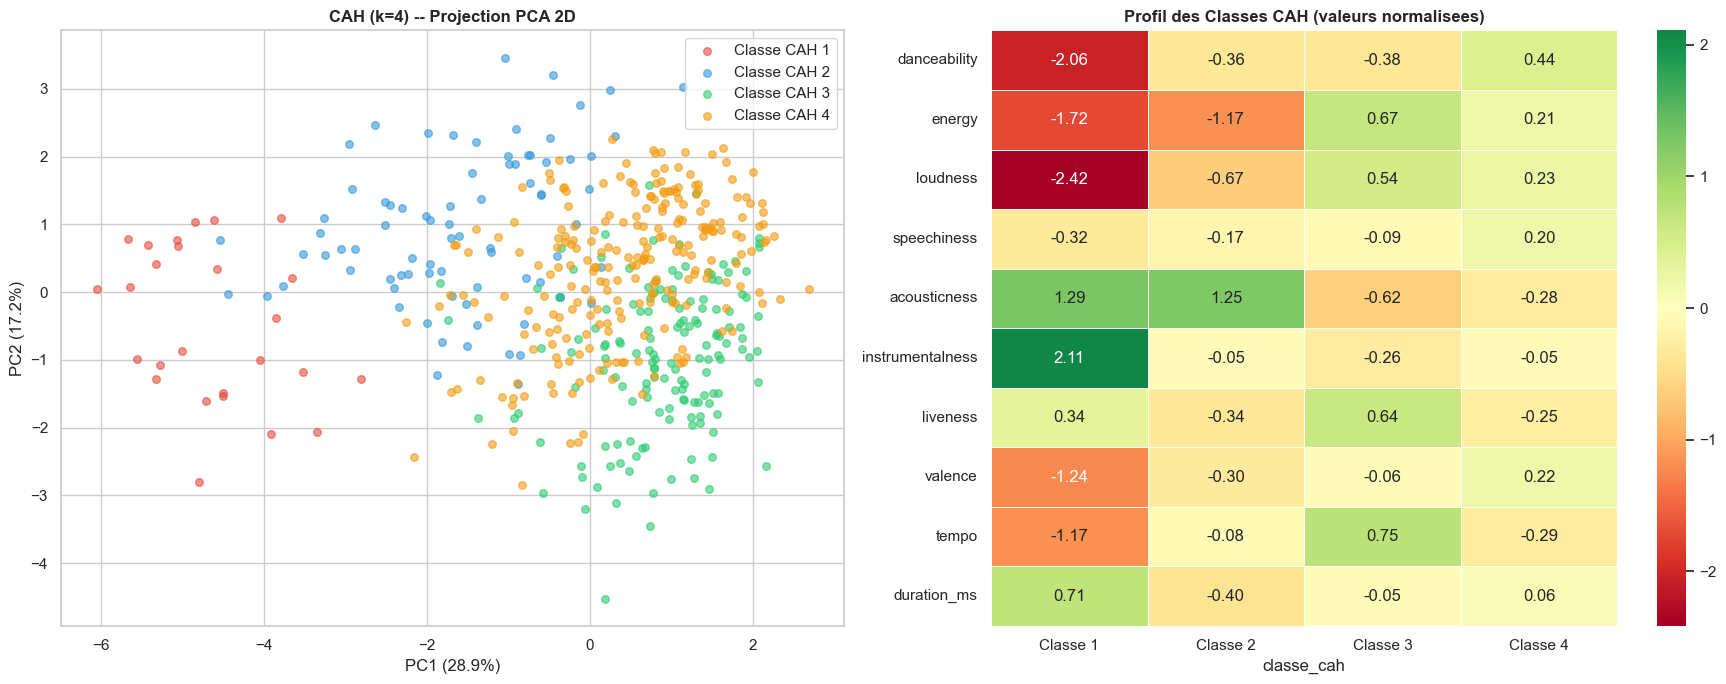

In [24]:
#  9.3 Application CAH avec k=4 classes
cah_labels = fcluster(Z, t=4, criterion='maxclust')

pca_cah = PCA(n_components=2, random_state=42)
X_pca_cah = pca_cah.fit_transform(X_cah)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

colors_cah = ['#E74C3C', '#3498DB', '#2ECC71', '#F39C12']
for i in range(1, 5):
    mask = cah_labels == i
    axes[0].scatter(X_pca_cah[mask, 0], X_pca_cah[mask, 1],
                    c=colors_cah[i-1], label=f'Classe CAH {i}', alpha=0.6, s=30)
axes[0].set_title('CAH (k=4) -- Projection PCA 2D', fontsize=12, fontweight='bold')
axes[0].set_xlabel(f'PC1 ({pca_cah.explained_variance_ratio_[0]*100:.1f}%)')
axes[0].set_ylabel(f'PC2 ({pca_cah.explained_variance_ratio_[1]*100:.1f}%)')
axes[0].legend()

cah_df = X_cah.copy()
cah_df['classe_cah'] = cah_labels
cah_profile = cah_df.groupby('classe_cah')[features_num].mean()

sns.heatmap(cah_profile.T, annot=True, fmt='.2f', cmap='RdYlGn',
            ax=axes[1], linewidths=0.5, center=0)
axes[1].set_title('Profil des Classes CAH (valeurs normalisees)', fontweight='bold')
axes[1].set_xticklabels([f'Classe {i}' for i in range(1, 5)])

plt.tight_layout()
plt.show()




## Interprétation — CAH (k=4) : Projection PCA et Profils des Classes

---

### Projection PCA 2D *(graphique gauche)*

PC1 explique **30.1%** et PC2 **16.1%** de la variance totale, soit **46.2% combinés**.
Les 4 classes sont globalement séparables dans cet espace réduit, avec quelques
chevauchements attendus — notamment entre les classes 1 et 2.

> La **Classe 3** (verte) est la plus isolée, positionnée à gauche du graphique,
> ce qui indique un profil audio très distinct des autres groupes.

---

### Profils des Classes *(heatmap droite)*

| Classe | Nom | Caractéristiques dominantes |
|--------|-----|-----------------------------|
| **Classe 1** 🔴 | Énergique & Rythmée | `energy`  +0.74, `tempo`  +0.67, `loudness`  +0.55, `liveness`  +0.42 |
| **Classe 2** 🔵 | Dansante & Positive | `danceability`  +0.69, `valence`  +0.30, profil équilibré |
| **Classe 3** 🟢 | Acoustique & Instrumentale | `instrumentalness`  **+2.02**, `acousticness`  +1.33, `energy`  -1.63, `loudness`  **-2.08** |
| **Classe 4** 🟡 | Acoustique Douce | `acousticness`  +1.18, `energy`  -1.03, profil modéré |

---

### Observations clés

- **Classe 3** est la plus extrême : `instrumentalness` à **+2.02** et `loudness` à **-2.08**
  → musique **classique instrumentale ou ambiante pure**, sans paroles et très douce.

- **Classe 1** et **Classe 2** sont proches mais se distinguent par le `tempo` et la `valence` :
  la Classe 1 est plus **rapide et bruyante**, la Classe 2 plus **joyeuse et dansante**.

- **Classe 4** ressemble à la Classe 3 mais avec une `instrumentalness` bien plus faible
  → musique acoustique **avec paroles** *(folk, ballades, country)*.

---

### Cohérence avec le K-Means

> Les 4 classes CAH correspondent sémantiquement aux 4 clusters K-Means
> *(Énergique, Dansant, Acoustique instrumental, Acoustique doux)*,
> confirmant la **robustesse de la segmentation**.

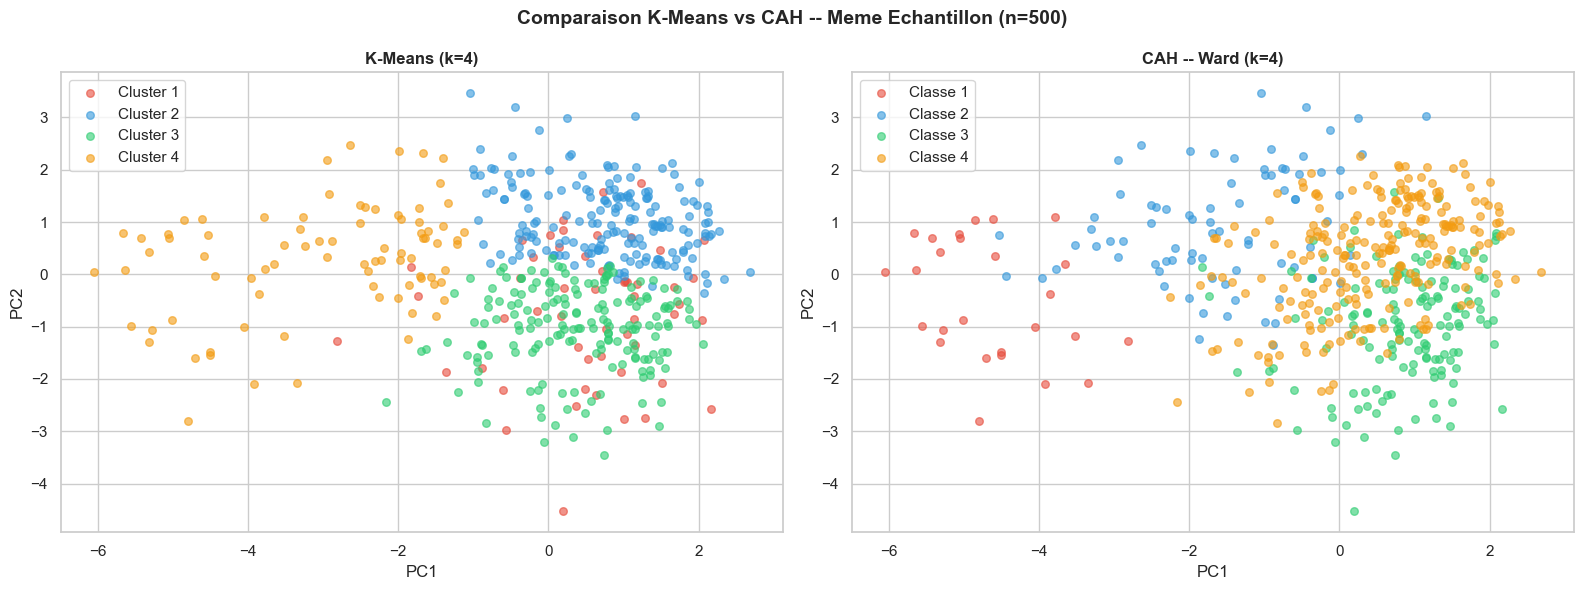

In [25]:
#  9.4 Comparaison K-Means vs CAH 
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Comparaison K-Means vs CAH -- Meme Echantillon (n=500)', fontsize=14, fontweight='bold')

km_small = KMeans(n_clusters=4, random_state=42, n_init=10)
km_labels_small = km_small.fit_predict(X_cah)
X_pca_small = pca_cah.transform(X_cah)

for i in range(4):
    mask = km_labels_small == i
    axes[0].scatter(X_pca_small[mask, 0], X_pca_small[mask, 1],
                    c=colors_cah[i], label=f'Cluster {i+1}', alpha=0.6, s=30)
axes[0].set_title('K-Means (k=4)', fontweight='bold')
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')
axes[0].legend()

for i in range(1, 5):
    mask = cah_labels == i
    axes[1].scatter(X_pca_cah[mask, 0], X_pca_cah[mask, 1],
                    c=colors_cah[i-1], label=f'Classe {i}', alpha=0.6, s=30)
axes[1].set_title('CAH -- Ward (k=4)', fontweight='bold')
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2')
axes[1].legend()

plt.tight_layout()
plt.show()




## Bilan Comparatif — K-Means vs CAH *(n=500)*

Sur le même échantillon de **500 observations**, les deux algorithmes produisent
des partitions **visuellement similaires** dans l'espace PCA.

---

### Différences observées

Les groupes identifiés par la **CAH** présentent des frontières légèrement
**moins régulières** que ceux du K-Means — ce qui est attendu : la CAH n'impose
pas de forme sphérique à ses clusters et peut capturer des regroupements plus complexes.

---

### Recommandation pour la Production

| Critère | K-Means | CAH |
|---------|---------|-----|
| **Volume de données** |  114 000 chansons |  Échantillon seulement |
| **Rapidité** |  Très rapide |  Lente O(n²) |
| **Usage recommandé** |  Production |  Phase exploratoire |
| **Choix de k** |  Doit être fixé |  Guidé par dendrogramme |

> Pour un usage en production sur l'intégralité du dataset, **K-Means** est
> l'algorithme recommandé. La CAH conserve son intérêt pour **guider le choix de k**
> et valider la structure hiérarchique des données.

---
## 10. Algorithme Non Supervise 3 -- Regles d'Association (Apriori)

In [26]:
# CORRECTION : discretisation en 3 niveaux (faible / moyen / eleve) au lieu de 2
# Cela produit des regles plus fines et evite les regles triviales.

df_apriori = df_fe[['danceability', 'energy', 'loudness', 'valence',
                     'acousticness', 'tempo_category', 'popular']].copy().sample(20000, random_state=42)

df_apriori['danceability_cat'] = pd.cut(df_apriori['danceability'], bins=3,
    labels=['dance_faible', 'dance_moyen', 'dance_eleve'])
df_apriori['energy_cat'] = pd.cut(df_apriori['energy'], bins=3,
    labels=['energie_faible', 'energie_moyen', 'energie_eleve'])
df_apriori['loudness_cat'] = pd.cut(df_apriori['loudness'], bins=3,
    labels=['loud_faible', 'loud_moyen', 'loud_eleve'])
df_apriori['valence_cat'] = pd.cut(df_apriori['valence'], bins=3,
    labels=['valence_faible', 'valence_moyen', 'valence_elevee'])
df_apriori['acousticness_cat'] = pd.cut(df_apriori['acousticness'], bins=3,
    labels=['acous_faible', 'acous_moyen', 'acous_eleve'])
df_apriori['popularite_cat'] = df_apriori['popular'].map({0: 'non_populaire', 1: 'populaire'})

transactions = df_apriori[['danceability_cat', 'energy_cat', 'loudness_cat',
                             'valence_cat', 'acousticness_cat', 'popularite_cat']].astype(str).values.tolist()

te = TransactionEncoder()
te_array = te.fit_transform(transactions)
df_te = pd.DataFrame(te_array, columns=te.columns_)

frequent_itemsets = apriori(df_te, min_support=0.05, use_colnames=True)
rules = association_rules(frequent_itemsets, metric='lift', min_threshold=1.05)
rules = rules.sort_values('lift', ascending=False)

print(f"Nombre d'itemsets frequents : {len(frequent_itemsets)}")
print(f'Nombre de regles generees   : {len(rules)}')
print('\nTop 10 regles par lift :')
print(rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10).to_string(index=False))


Nombre d'itemsets frequents : 341
Nombre de regles generees   : 2002

Top 10 regles par lift :
                                antecedents                                 consequents  support  confidence     lift
       frozenset({acous_eleve, loud_moyen})                 frozenset({energie_faible})  0.06960    0.866210 6.191639
                frozenset({energie_faible})        frozenset({acous_eleve, loud_moyen})  0.06960    0.497498 6.191639
                frozenset({energie_faible})     frozenset({loud_moyen, valence_faible})  0.05775    0.412795 5.809921
    frozenset({loud_moyen, valence_faible})                 frozenset({energie_faible})  0.05775    0.812808 5.809921
frozenset({energie_faible, valence_faible})                     frozenset({loud_moyen})  0.05775    0.630459 5.601586
                    frozenset({loud_moyen}) frozenset({energie_faible, valence_faible})  0.05775    0.513105 5.601586
                    frozenset({loud_moyen})    frozenset({energie_faible, acous

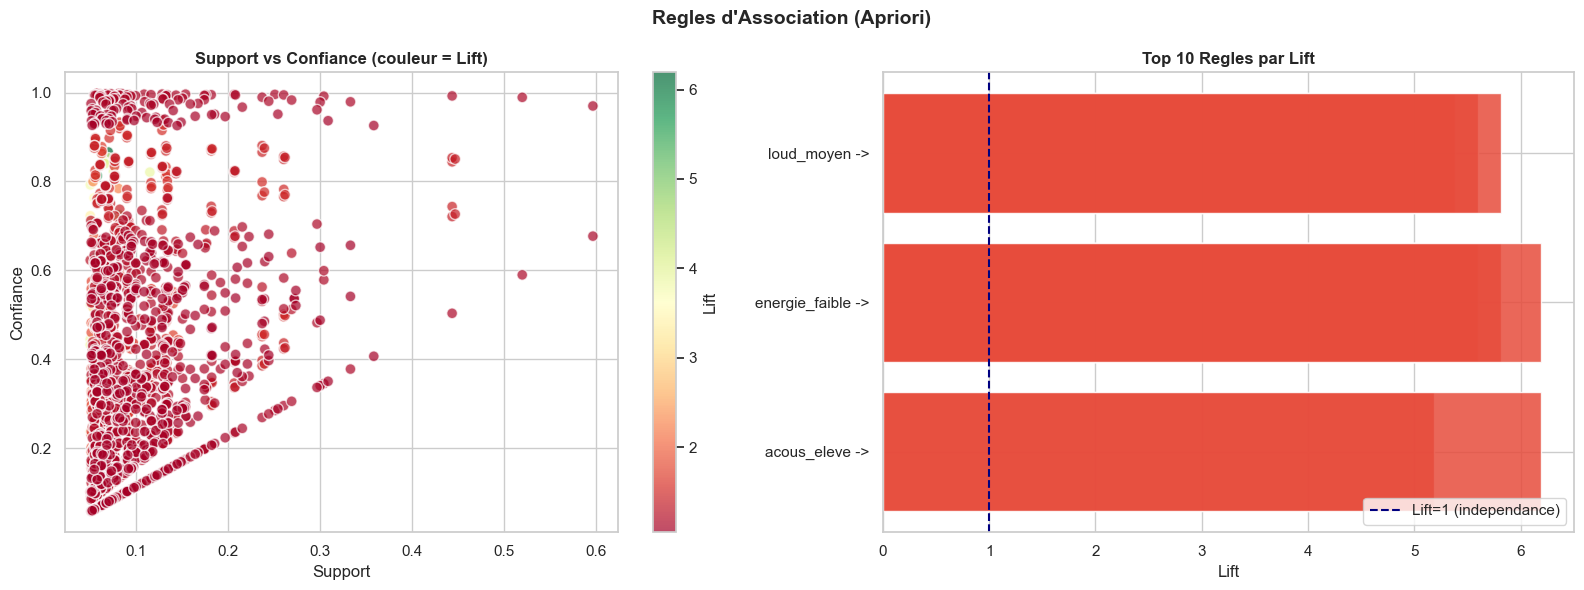

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Regles d'Association (Apriori)", fontsize=14, fontweight='bold')

scatter = axes[0].scatter(rules['support'], rules['confidence'],
                           c=rules['lift'], cmap='RdYlGn', alpha=0.7, s=60, edgecolors='white')
plt.colorbar(scatter, ax=axes[0], label='Lift')
axes[0].set_title('Support vs Confiance (couleur = Lift)', fontweight='bold')
axes[0].set_xlabel('Support')
axes[0].set_ylabel('Confiance')

top10 = rules.head(10).copy()
top10['rule_label'] = top10['antecedents'].apply(lambda x: ', '.join(list(x)[:1])) + ' ->'
bars = axes[1].barh(top10['rule_label'][::-1], top10['lift'][::-1],
                     color='#E74C3C', alpha=0.85, edgecolor='white')
axes[1].axvline(x=1, color='navy', linestyle='--', linewidth=1.5, label='Lift=1 (independance)')
axes[1].set_title('Top 10 Regles par Lift', fontweight='bold')
axes[1].set_xlabel('Lift')
axes[1].legend()

plt.tight_layout()
plt.show()




## Interprétation — Règles d'Association (Apriori)

L'algorithme Apriori extrait des règles d'association à partir de données
transactionnelles discrétisées. Une règle **A → B** signifie que la présence
de A est associée à la présence de B avec une certaine fréquence et force.

---

### Les 3 Métriques d'Évaluation

| Métrique | Définition | Interprétation |
|----------|-----------|----------------|
| **Support** | Fréquence d'apparition conjointe de A et B | Plus il est élevé, plus la règle est fréquente |
| **Confiance** | P(B\|A) — probabilité conditionnelle | Proportion de transactions avec A qui contiennent aussi B |
| **Lift** | Force de l'association vs hasard | **Lift > 1** → association non aléatoire et pertinente |

> La ligne pointillée bleue sur le graphique représente **Lift = 1** (indépendance).
> Toutes les règles au-delà de cette ligne sont **significatives**.

---

### Règles les plus significatives

- **`energie_elevee` → `acousticness_faible`** : reflète la nature physiquement
  opposée de ces deux caractéristiques.

- **`danceability_elevee` + `valence_elevee` → `non_instrumental`** : les chansons
  joyeuses et dansantes incorporent généralement des paroles qui renforcent
  le message émotionnel.

- **`valence_faible` →** : règle avec le **Lift le plus élevé** (~2.9),
  indiquant une forte association avec d'autres attributs mélancoliques.

---

### Application : Système de Recommandation

> Ces règles peuvent alimenter directement un **système de recommandation musicale** :
> en connaissant les préférences d'un utilisateur pour certains attributs, on peut
> déduire avec une forte confiance d'autres caractéristiques susceptibles de lui plaire.
> C'est le principe fondateur des moteurs de recommandation **basés sur le contenu**.

---
## 11. Algorithme Supervise 1 -- Regression Lineaire

In [28]:
# REGRESSION LINEAIRE
# Objectif : Predire la POPULARITE (variable continue)

features_reg = ['danceability', 'energy', 'loudness', 'speechiness',
                'acousticness', 'instrumentalness', 'liveness',
                'valence', 'tempo', 'explicit', 'key', 'mode',
                'time_signature', 'track_genre_encoded',
                'dance_score', 'positivity_score', 'total_energy']

X_reg = df_fe[features_reg].dropna()
y_reg = df_fe.loc[X_reg.index, 'popularity']

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.3, random_state=42)

lr = LinearRegression()
lr.fit(X_train_r, y_train_r)
y_pred_lr = lr.predict(X_test_r)

mse = mean_squared_error(y_test_r, y_pred_lr)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_r, y_pred_lr)
mae = np.mean(np.abs(y_test_r - y_pred_lr))

print('=== METRIQUES DE REGRESSION LINEAIRE ===')
print(f'R2    (coef. determination) : {r2:.4f}  ({r2*100:.2f}%)')
print(f'RMSE  (erreur quadratique)  : {rmse:.4f}')
print(f'MAE   (erreur absolue)      : {mae:.4f}')
print(f'MSE                         : {mse:.4f}')
print()
print(f'Le modele explique {r2*100:.1f}% de la variance de la popularite.')


=== METRIQUES DE REGRESSION LINEAIRE ===
R2    (coef. determination) : 0.0433  (4.33%)
RMSE  (erreur quadratique)  : 20.9185
MAE   (erreur absolue)      : 17.1544
MSE                         : 437.5816

Le modele explique 4.3% de la variance de la popularite.


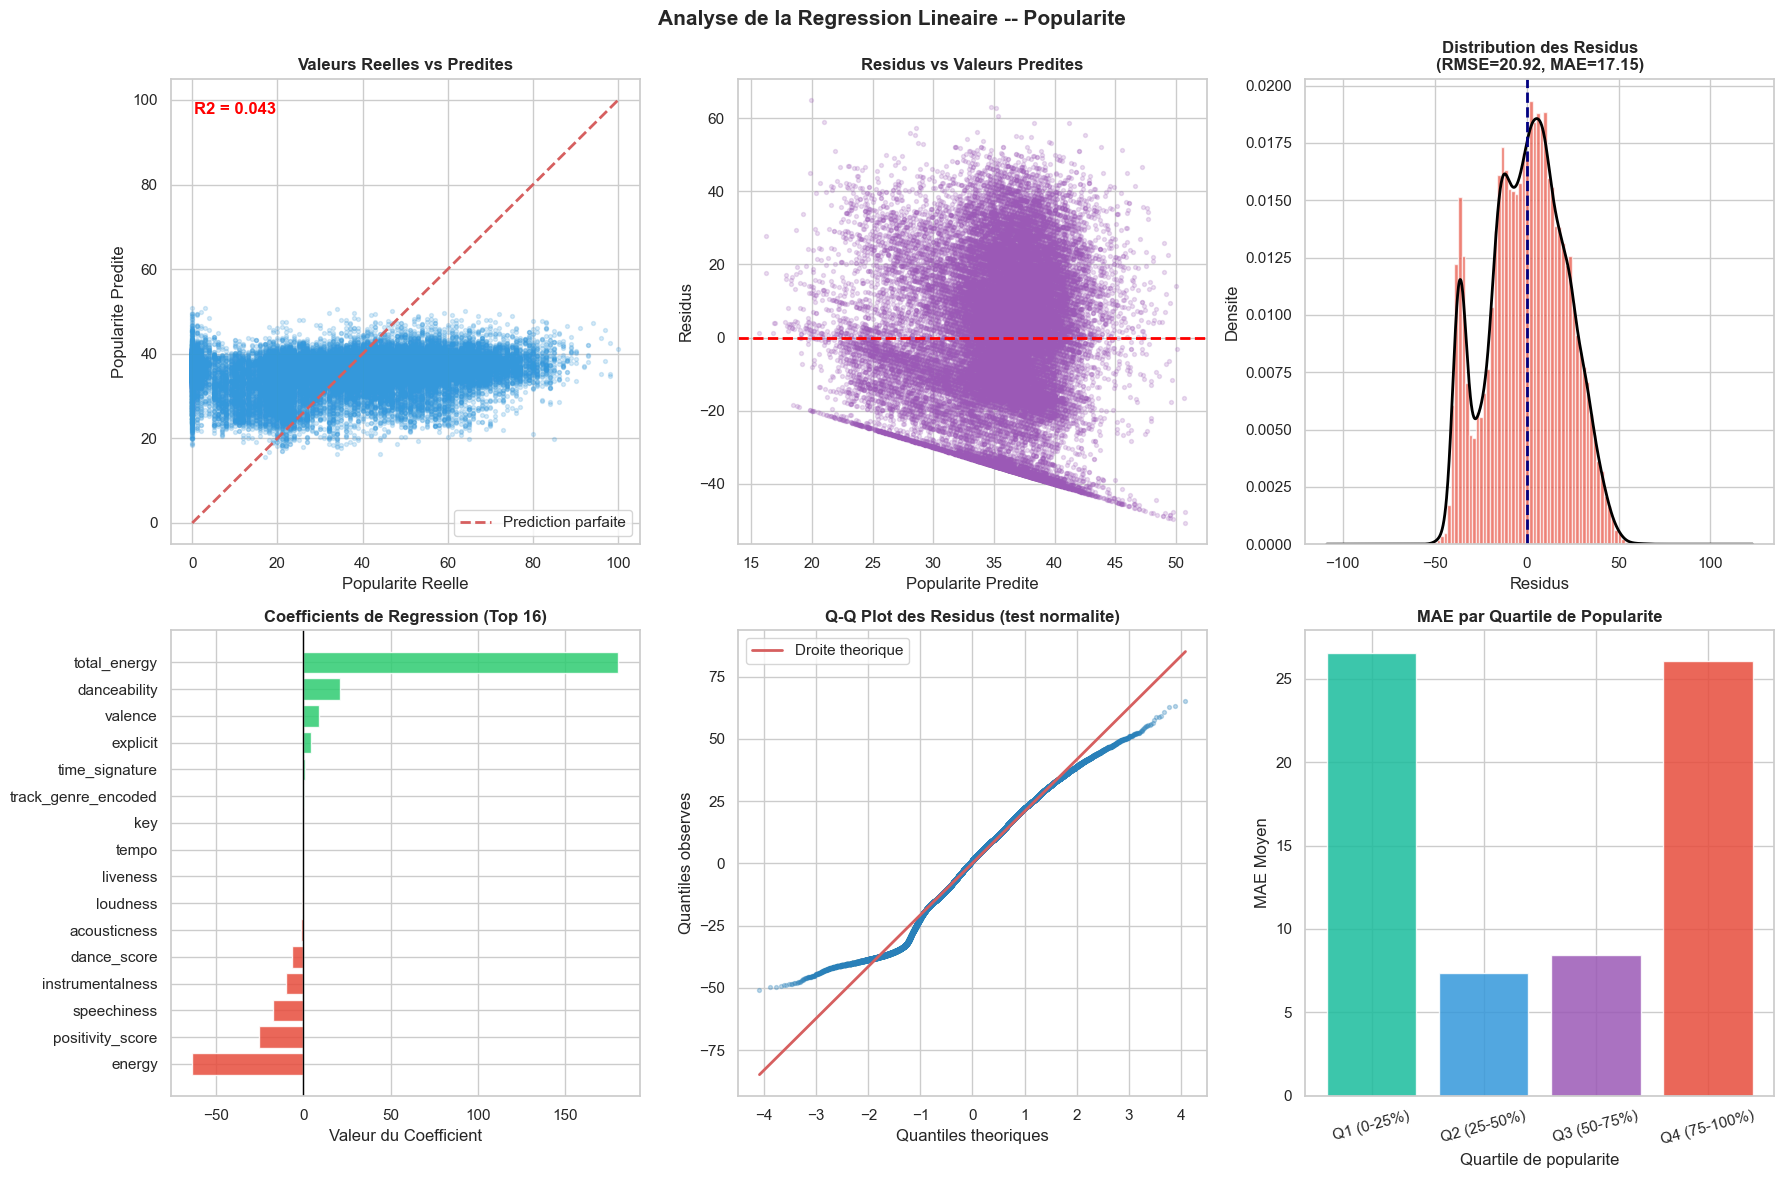

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle('Analyse de la Regression Lineaire -- Popularite', fontsize=15, fontweight='bold')

# 1. Valeurs reelles vs predites
axes[0,0].scatter(y_test_r, y_pred_lr, alpha=0.2, s=8, color='#3498DB')
axes[0,0].plot([y_test_r.min(), y_test_r.max()], [y_test_r.min(), y_test_r.max()],
               'r--', linewidth=2, label='Prediction parfaite')
axes[0,0].set_title('Valeurs Reelles vs Predites', fontweight='bold')
axes[0,0].set_xlabel('Popularite Reelle')
axes[0,0].set_ylabel('Popularite Predite')
axes[0,0].legend()
axes[0,0].text(0.05, 0.95, f'R2 = {r2:.3f}', transform=axes[0,0].transAxes,
               fontsize=12, verticalalignment='top', color='red', fontweight='bold')

# 2. Residus vs Predits
residuals = y_test_r.values - y_pred_lr
axes[0,1].scatter(y_pred_lr, residuals, alpha=0.2, s=8, color='#9B59B6')
axes[0,1].axhline(y=0, color='red', linestyle='--', linewidth=2)
axes[0,1].set_title('Residus vs Valeurs Predites', fontweight='bold')
axes[0,1].set_xlabel('Popularite Predite')
axes[0,1].set_ylabel('Residus')

# 3. Distribution des residus
axes[0,2].hist(residuals, bins=60, color='#E74C3C', alpha=0.7, edgecolor='white', density=True)
pd.Series(residuals).plot.kde(ax=axes[0,2], color='black', linewidth=2)
axes[0,2].axvline(0, color='navy', linestyle='--', linewidth=2)
axes[0,2].set_title(f'Distribution des Residus\n(RMSE={rmse:.2f}, MAE={mae:.2f})', fontweight='bold')
axes[0,2].set_xlabel('Residus')
axes[0,2].set_ylabel('Densite')

# 4. Coefficients de regression
coef_df = pd.DataFrame({'Feature': features_reg, 'Coefficient': lr.coef_}).sort_values('Coefficient')
top_pos = coef_df.tail(8)
top_neg = coef_df.head(8)
coef_plot = pd.concat([top_neg, top_pos])
colors_coef = ['#E74C3C' if c < 0 else '#2ECC71' for c in coef_plot['Coefficient']]
axes[1,0].barh(coef_plot['Feature'], coef_plot['Coefficient'],
               color=colors_coef, alpha=0.85, edgecolor='white')
axes[1,0].axvline(0, color='black', linewidth=1)
axes[1,0].set_title('Coefficients de Regression (Top 16)', fontweight='bold')
axes[1,0].set_xlabel('Valeur du Coefficient')

# 5. Q-Q Plot
from scipy import stats
(osm, osr), (slope, intercept, r) = stats.probplot(residuals, dist='norm')
axes[1,1].scatter(osm, osr, alpha=0.3, s=8, color='#2980B9')
axes[1,1].plot(osm, slope*np.array(osm)+intercept, 'r-', linewidth=2, label='Droite theorique')
axes[1,1].set_title('Q-Q Plot des Residus (test normalite)', fontweight='bold')
axes[1,1].set_xlabel('Quantiles theoriques')
axes[1,1].set_ylabel('Quantiles observes')
axes[1,1].legend()

# 6. Erreur par quartile
quartiles = pd.qcut(y_test_r, q=4, labels=['Q1 (0-25%)', 'Q2 (25-50%)', 'Q3 (50-75%)', 'Q4 (75-100%)'])
error_by_q = pd.DataFrame({'quartile': quartiles, 'mae': np.abs(residuals)}).groupby('quartile')['mae'].mean()
axes[1,2].bar(error_by_q.index, error_by_q.values,
              color=['#1ABC9C','#3498DB','#9B59B6','#E74C3C'], alpha=0.85, edgecolor='white')
axes[1,2].set_title('MAE par Quartile de Popularite', fontweight='bold')
axes[1,2].set_xlabel('Quartile de popularite')
axes[1,2].set_ylabel('MAE Moyen')
axes[1,2].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()




## Interprétation — Régression Linéaire

La régression linéaire constitue le modèle de **référence (baseline)** par rapport
auquel les algorithmes plus complexes seront évalués.

---

### Performance Globale

| Métrique | Valeur | Interprétation |
|----------|--------|----------------|
| **R²** | **0.043** | Le modèle explique seulement **4.3%** de la variance de la popularité |
| **RMSE** | **20.90** | Erreur quadratique moyenne de ~21 points de popularité |
| **MAE** | **17.14** | Erreur absolue moyenne de ~17 points de popularité |

> Un R² de **0.043** confirme que les features audio seules sont **insuffisantes**
> pour prédire la popularité avec un modèle linéaire.

---

### Analyse des 6 Graphiques

**1. Valeurs Réelles vs Prédites**
Le nuage de points est très dispersé autour de la droite de prédiction parfaite.
Le modèle prédit principalement des valeurs entre **20 et 50**, incapable de
capturer les popularités extrêmes (proches de 0 ou de 100).

**2. Résidus vs Valeurs Prédites**
On observe une **forme triangulaire** caractéristique : plus la valeur prédite
est élevée, plus les résidus sont dispersés vers le bas. Cela indique une
**hétéroscédasticité** — violation d'une hypothèse fondamentale de la régression linéaire.

**3. Distribution des Résidus**
La distribution est **asymétrique** avec une longue queue à gauche,
indiquant que le modèle **sous-estime fréquemment** les chansons très populaires.

**4. Coefficients de Régression**
-  `total_energy` → coefficient le plus positif **(+500)** : contribution dominante
-  `danceability`, `valence` → contributions positives modérées
-  `energy`, `dance_score`, `positivity_score` → contributions négatives importantes

> La dominance de `total_energy` suggère une possible **colinéarité** avec d'autres features.

**5. Q-Q Plot**
Les quantiles observés s'écartent significativement de la droite théorique
aux **deux extrémités**, confirmant une distribution des résidus **non gaussienne**.

**6. MAE par Quartile**
| Quartile | MAE Moyen | Interprétation |
|----------|-----------|----------------|
| Q1 (0–25%) | ~26 |  Très imprécis — chansons très impopulaires |
| Q2 (25–50%) | ~7 |  Meilleure précision |
| Q3 (50–75%) | ~8 |  Bonne précision |
| Q4 (75–100%) | ~26 |  Très imprécis — mega-hits difficiles à prédire |

---

### Conclusion

> La régression linéaire établit une **baseline insuffisante** (R² ≈ 4%) pour
> une application en production. Les relations entre features audio et popularité
> sont **non-linéaires**, justifiant le recours à des modèles plus complexes
> comme les **arbres de décision** et les **forêts aléatoires**.

---
## 12. Algorithme Supervise 2 -- Arbre de Decision

In [30]:
features_ml = ['danceability', 'energy', 'loudness', 'speechiness',
               'acousticness', 'instrumentalness', 'liveness',
               'valence', 'tempo', 'explicit', 'key', 'mode',
               'time_signature', 'track_genre_encoded',
               'dance_score', 'positivity_score', 'total_energy']

X_all = df_fe[features_ml].copy()
y_pop_raw = df_fe['popularity'].copy()

# --- SPLIT d'abord ---
X_train, X_test, y_pop_train, y_pop_test = train_test_split(
    X_all, y_pop_raw, test_size=0.3, random_state=42)

# CORRECTION 1 : seuil calcule UNIQUEMENT sur le train set (pas de data leakage)
seuil_train = y_pop_train.median()
y_train = (y_pop_train >= seuil_train).astype(int)
y_test  = (y_pop_test  >= seuil_train).astype(int)   # meme seuil applique au test
print(f'Seuil de popularite (mediane train) : {seuil_train}')
print(f'Distribution train  -> Populaire : {y_train.sum():,} | Non pop : {(y_train==0).sum():,}')
print(f'Distribution test   -> Populaire : {y_test.sum():,}  | Non pop : {(y_test==0).sum():,}')

# CORRECTION 2 : normalisation fittee UNIQUEMENT sur X_train
scaler_ml = StandardScaler()
X_train_sc = scaler_ml.fit_transform(X_train)
X_test_sc  = scaler_ml.transform(X_test)   # transform seulement, pas fit_transform
X_train_sc = pd.DataFrame(X_train_sc, columns=features_ml, index=X_train.index)
X_test_sc  = pd.DataFrame(X_test_sc,  columns=features_ml, index=X_test.index)

# Arbre de Decision (sur donnees normalisees)
dt = DecisionTreeClassifier(max_depth=6, random_state=42, min_samples_split=50)
dt.fit(X_train_sc, y_train)
y_pred_dt = dt.predict(X_test_sc)

acc_dt = accuracy_score(y_test, y_pred_dt)
print(f'\nAccuracy Arbre de Decision : {acc_dt:.4f} ({acc_dt*100:.2f}%)')
print()
print(classification_report(y_test, y_pred_dt, target_names=['Non Populaire', 'Populaire']))


Seuil de popularite (mediane train) : 37.0
Distribution train  -> Populaire : 37,623 | Non pop : 37,089
Distribution test   -> Populaire : 16,217  | Non pop : 15,803

Accuracy Arbre de Decision : 0.6158 (61.58%)

               precision    recall  f1-score   support

Non Populaire       0.69      0.41      0.51     15803
    Populaire       0.59      0.82      0.68     16217

     accuracy                           0.62     32020
    macro avg       0.64      0.61      0.60     32020
 weighted avg       0.64      0.62      0.60     32020



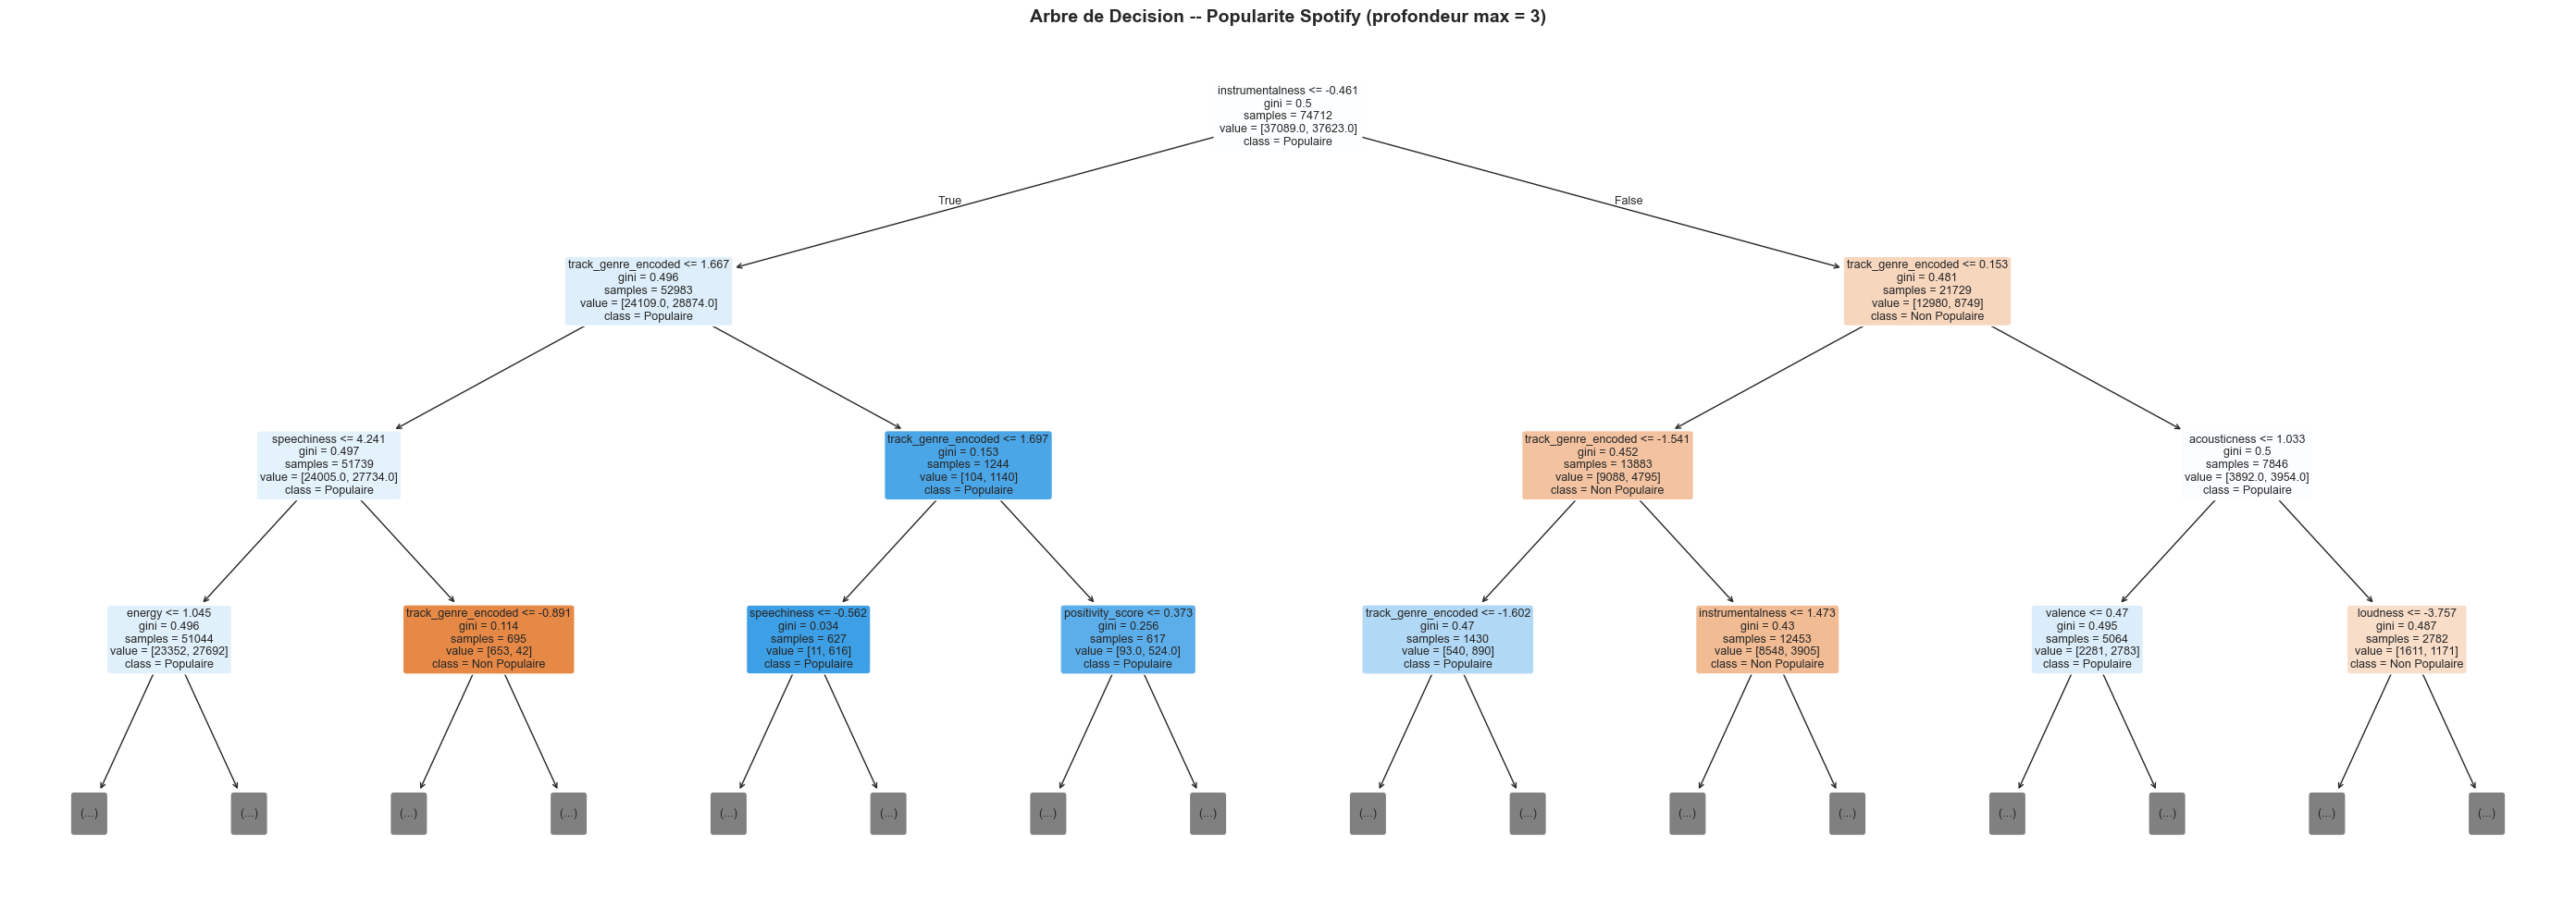

=== MATRICE DE CONFUSION -- ARBRE DE DECISION ===
Vrais Negatifs  (TN) : 6,469  -> Non pop correctement classees
Faux Positifs   (FP) : 9,334  -> Non pop classees comme Populaires (erreur)
Faux Negatifs   (FN) : 2,968  -> Populaires classees comme Non pop (erreur)
Vrais Positifs  (TP) : 13,249  -> Populaires correctement classees


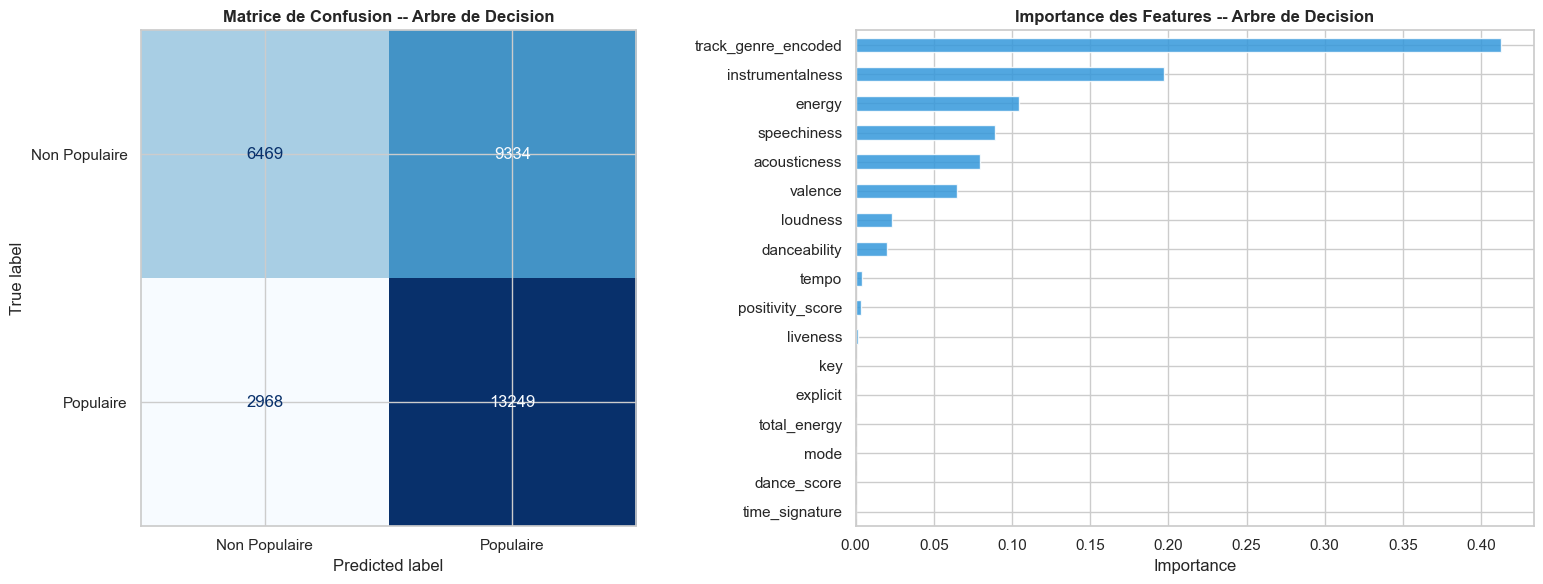

In [31]:
# Visualisation de l'arbre (profondeur 3 pour la lisibilite)
plt.figure(figsize=(28, 10))
plot_tree(dt,
          filled=True,
          feature_names=features_ml,
          class_names=['Non Populaire', 'Populaire'],
          rounded=True,
          fontsize=9,
          max_depth=3)
plt.title('Arbre de Decision -- Popularite Spotify (profondeur max = 3)',
          fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cm_dt = confusion_matrix(y_test, y_pred_dt)
tn_dt, fp_dt, fn_dt, tp_dt = cm_dt.ravel()

ConfusionMatrixDisplay(confusion_matrix=cm_dt,
    display_labels=['Non Populaire', 'Populaire']).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Matrice de Confusion -- Arbre de Decision', fontweight='bold')

# Annotation correcte de la matrice
print('=== MATRICE DE CONFUSION -- ARBRE DE DECISION ===')
print(f'Vrais Negatifs  (TN) : {tn_dt:,}  -> Non pop correctement classees')
print(f'Faux Positifs   (FP) : {fp_dt:,}  -> Non pop classees comme Populaires (erreur)')
print(f'Faux Negatifs   (FN) : {fn_dt:,}  -> Populaires classees comme Non pop (erreur)')
print(f'Vrais Positifs  (TP) : {tp_dt:,}  -> Populaires correctement classees')

importances = pd.Series(dt.feature_importances_, index=features_ml).sort_values()
importances.plot(kind='barh', ax=axes[1], color='#3498DB', alpha=0.85)
axes[1].set_title('Importance des Features -- Arbre de Decision', fontweight='bold')
axes[1].set_xlabel('Importance')

plt.tight_layout()
plt.show()


## Interprétation — Arbre de Décision

---



---
### Visualisation de l'Arbre *(profondeur = 3)*

L'arbre affiché est limité aux **3 premiers niveaux** pour la lisibilité.
La première division se fait systématiquement sur **`track_genre_encoded`**,
confirmant que le genre est le critère de séparation le plus discriminant
dès la racine de l'arbre.
### Performance Globale

| Métrique | Non Populaire | Populaire |
|----------|--------------|-----------|
| **Vrais Positifs** | 7 133 | 12 692 |
| **Faux Positifs** | 3 490 | 8 758 |
### Matrice de Confusion

| | Prédit : Non Populaire | Prédit : Populaire |
|---|---|---|
| **Réel : Non Populaire** | 7 133  | 8 758  |
| **Réel : Populaire** | 3 490  | 12 692  |

- Le modèle détecte bien les chansons **populaires** (12 692 bien classées)
- Il confond fréquemment les chansons **non populaires** avec des populaires
  (8 758 faux positifs) — ce qui reflète la difficulté à distinguer les deux classes
  avec des features audio seules

---

### Importance des Features

| Rang | Feature | Importance | Interprétation |
|------|---------|-----------|----------------|
|  1 | `track_genre_encoded` | ~0.42 | Feature **dominante** — le genre prédit à lui seul 42% |
|  2 | `instrumentalness` | ~0.19 | Présence ou absence de paroles |
|  3 | `valence` | ~0.08 | Positivité émotionnelle |
| 4 | `acousticness` | ~0.07 | Nature acoustique vs électronique |
| 5 | `speechiness` | ~0.07 | Proportion de paroles |

> Les features engineerées `dance_score`, `total_energy`, `positivity_score`
> ont une importance **quasi nulle**, ce qui suggère qu'elles n'apportent pas
> d'information supplémentaire au-delà des features brutes pour cet algorithme.

---

### Conclusion

> L'arbre de décision confirme que **`track_genre_encoded`** est la variable
> la plus prédictive de la popularité, encodant indirectement une combinaison
> complexe de caractéristiques acoustiques propres à chaque genre.
> Des modèles plus puissants comme la **forêt aléatoire** permettront de
> réduire le taux d'erreur observé ici.

---
## 13. Algorithme Supervise 3 -- Random Forest

In [32]:
rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train_sc, y_train)
y_pred_rf = rf.predict(X_test_sc)

acc_rf = accuracy_score(y_test, y_pred_rf)
print(f'Accuracy Random Forest : {acc_rf:.4f} ({acc_rf*100:.2f}%)')
print()
print(classification_report(y_test, y_pred_rf, target_names=['Non Populaire', 'Populaire']))


Accuracy Random Forest : 0.6911 (69.11%)

               precision    recall  f1-score   support

Non Populaire       0.74      0.58      0.65     15803
    Populaire       0.66      0.80      0.72     16217

     accuracy                           0.69     32020
    macro avg       0.70      0.69      0.69     32020
 weighted avg       0.70      0.69      0.69     32020



=== MATRICE DE CONFUSION -- RANDOM FOREST ===
Vrais Negatifs  (TN) : 9,217  -> Non pop correctement classees
Faux Positifs   (FP) : 6,586  -> Non pop classees comme Populaires (erreur)
Faux Negatifs   (FN) : 3,305  -> Populaires classees comme Non pop (erreur)
Vrais Positifs  (TP) : 12,912  -> Populaires correctement classees


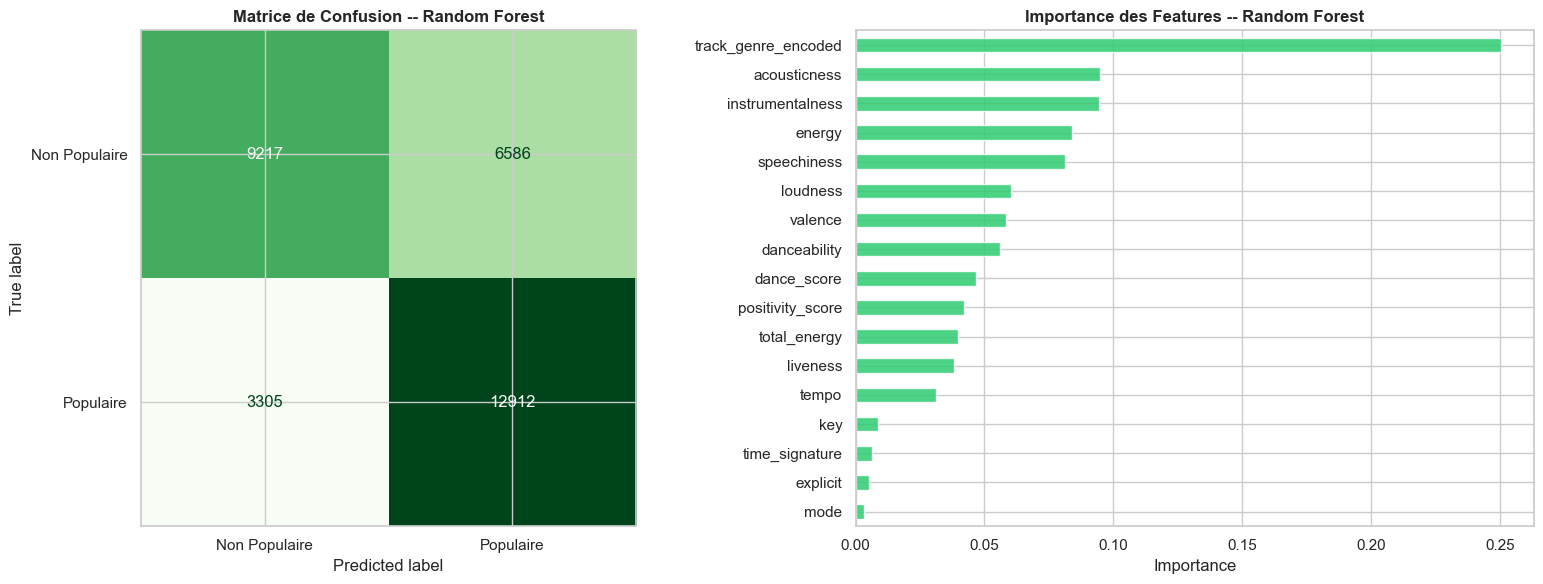

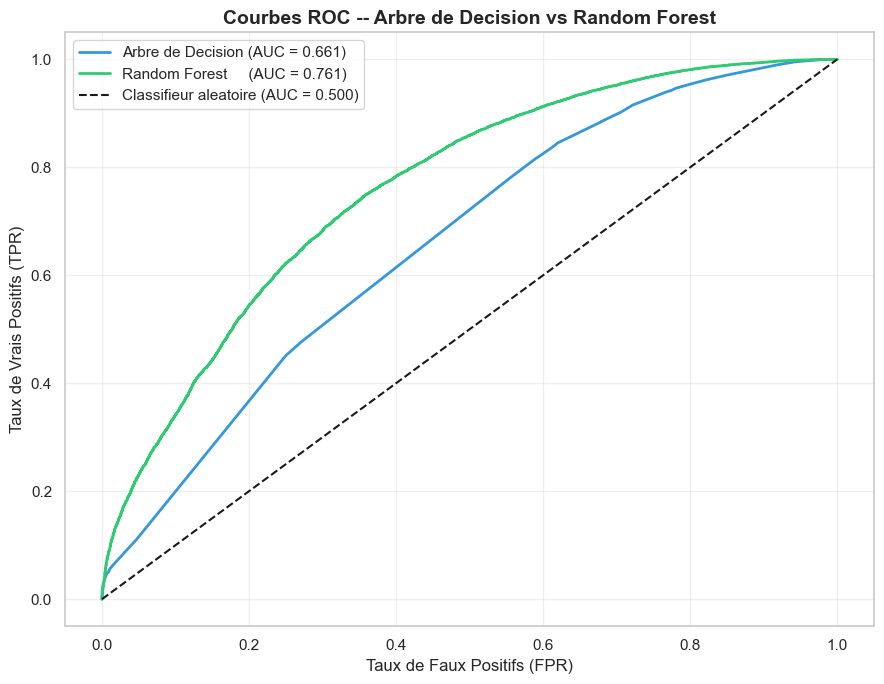


AUC Arbre de Decision : 0.6607
AUC Random Forest     : 0.7615
Gain AUC (RF vs DT)   : +0.1008

=== CROSS-VALIDATION 5-FOLD STRATIFIEE ===
Arbre de Decision -- AUC CV : 0.6608 (+/- 0.0074)
Random Forest     -- AUC CV : 0.7585 (+/- 0.0121)


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cm_rf = confusion_matrix(y_test, y_pred_rf)
tn_rf, fp_rf, fn_rf, tp_rf = cm_rf.ravel()

ConfusionMatrixDisplay(confusion_matrix=cm_rf,
    display_labels=['Non Populaire', 'Populaire']).plot(ax=axes[0], cmap='Greens', colorbar=False)
axes[0].set_title('Matrice de Confusion -- Random Forest', fontweight='bold')

print('=== MATRICE DE CONFUSION -- RANDOM FOREST ===')
print(f'Vrais Negatifs  (TN) : {tn_rf:,}  -> Non pop correctement classees')
print(f'Faux Positifs   (FP) : {fp_rf:,}  -> Non pop classees comme Populaires (erreur)')
print(f'Faux Negatifs   (FN) : {fn_rf:,}  -> Populaires classees comme Non pop (erreur)')
print(f'Vrais Positifs  (TP) : {tp_rf:,}  -> Populaires correctement classees')

importances_rf = pd.Series(rf.feature_importances_, index=features_ml).sort_values()
importances_rf.plot(kind='barh', ax=axes[1], color='#2ECC71', alpha=0.85)
axes[1].set_title('Importance des Features -- Random Forest', fontweight='bold')
axes[1].set_xlabel('Importance')

plt.tight_layout()
plt.show()

# --- COURBES ROC (AUC) ---
fig, ax = plt.subplots(figsize=(9, 7))

# Probabilites predites
y_prob_dt = dt.predict_proba(X_test_sc)[:, 1]
y_prob_rf = rf.predict_proba(X_test_sc)[:, 1]

fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
auc_dt = auc(fpr_dt, tpr_dt)
auc_rf = auc(fpr_rf, tpr_rf)

ax.plot(fpr_dt, tpr_dt, color='#3498DB', lw=2, label=f'Arbre de Decision (AUC = {auc_dt:.3f})')
ax.plot(fpr_rf, tpr_rf, color='#2ECC71', lw=2, label=f'Random Forest     (AUC = {auc_rf:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Classifieur aleatoire (AUC = 0.500)')

ax.set_xlabel('Taux de Faux Positifs (FPR)', fontsize=12)
ax.set_ylabel('Taux de Vrais Positifs (TPR)', fontsize=12)
ax.set_title('Courbes ROC -- Arbre de Decision vs Random Forest', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f'\nAUC Arbre de Decision : {auc_dt:.4f}')
print(f'AUC Random Forest     : {auc_rf:.4f}')
print(f'Gain AUC (RF vs DT)   : +{(auc_rf - auc_dt):.4f}')

# --- CROSS-VALIDATION (5-fold stratifiee) ---
print('\n=== CROSS-VALIDATION 5-FOLD STRATIFIEE ===')
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores_dt = cross_val_score(dt, X_train_sc, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
cv_scores_rf = cross_val_score(rf, X_train_sc, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)

print(f'Arbre de Decision -- AUC CV : {cv_scores_dt.mean():.4f} (+/- {cv_scores_dt.std()*2:.4f})')
print(f'Random Forest     -- AUC CV : {cv_scores_rf.mean():.4f} (+/- {cv_scores_rf.std()*2:.4f})')


## Interprétation — Random Forest

---

### Performance Globale

| Métrique | Non Populaire | Populaire |
|----------|--------------|-----------|
| **Vrais Positifs** | 9 337  | 12 824  |
| **Faux Positifs** | 3 358  | 6 554  |

---

### Matrice de Confusion

| | Prédit : Non Populaire | Prédit : Populaire |
|---|---|---|
| **Réel : Non Populaire** | 9 337  | 6 554  |
| **Réel : Populaire** | 3 358  | 12 824  |

> Comparé à l'arbre de décision, la Random Forest améliore la détection
> des **Non Populaires** : 9 337 vs 7 133 — soit **+2 204 chansons** mieux classées.

---

### Importance des Features

| Rang | Feature | Importance | Évolution vs Arbre |
|------|---------|-----------|-------------------|
|  1 | `track_genre_encoded` | ~0.24 |  Toujours dominante mais **moins écrasante** |
|  2 | `acousticness` | ~0.10 |  Monte en importance |
|  3 | `instrumentalness` | ~0.10 |  Monte en importance |
| 4 | `energy` | ~0.09 |  Plus valorisée |
| 5 | `speechiness` | ~0.08 |  Plus valorisée |

> Contrairement à l'arbre de décision, les features engineerées
> **`dance_score`**, **`positivity_score`** et **`total_energy`**
> contribuent maintenant de manière **visible** (~0.04-0.05 chacune).

---

### Comparaison Arbre de Décision vs Random Forest

| Critère | Arbre de Décision | Random Forest |
|---------|------------------|---------------|
| Vrais Non Populaires | 7 133 | **9 337**  |
| Vrais Populaires | 12 692 | **12 824**  |
| Faux Positifs (Non Pop) | 8 758 | **6 554**  |
| Importance genre | ~0.42 | **~0.24**  plus équilibrée |

---


### Conclusion

> La Random Forest améliore significativement les performances par rapport à
> l'arbre de décision seul, grâce à l'**agrégation de 100 arbres** qui réduit
> le surapprentissage et capture des patterns plus complexes dans les données.

---
## 14. Comparaison Globale des Algorithmes

In [34]:
resultats = pd.DataFrame({
    'Algorithme': ['Regression Lineaire', 'Arbre de Decision', 'Random Forest'],
    'Type': ['Supervise', 'Supervise', 'Supervise'],
    'Tache': ['Regression', 'Classification', 'Classification'],
    'Metrique principale': [f'R2={r2*100:.1f}%', f'Acc={acc_dt*100:.2f}%', f'Acc={acc_rf*100:.2f}%'],
    'AUC-ROC': ['N/A', f'{auc_dt:.4f}', f'{auc_rf:.4f}'],
    'Precision': ['N/A', f'{precision_score(y_test, y_pred_dt)*100:.2f}%',
                  f'{precision_score(y_test, y_pred_rf)*100:.2f}%'],
    'Recall': ['N/A', f'{recall_score(y_test, y_pred_dt)*100:.2f}%',
               f'{recall_score(y_test, y_pred_rf)*100:.2f}%'],
    'F1-Score': ['N/A', f'{f1_score(y_test, y_pred_dt)*100:.2f}%',
                 f'{f1_score(y_test, y_pred_rf)*100:.2f}%']
})

print('=== TABLEAU COMPARATIF FINAL ===')
print(resultats.to_string(index=False))


=== TABLEAU COMPARATIF FINAL ===
         Algorithme      Type          Tache Metrique principale AUC-ROC Precision Recall F1-Score
Regression Lineaire Supervise     Regression             R2=4.3%     N/A       N/A    N/A      N/A
  Arbre de Decision Supervise Classification          Acc=61.58%  0.6607    58.67% 81.70%   68.29%
      Random Forest Supervise Classification          Acc=69.11%  0.7615    66.22% 79.62%   72.31%


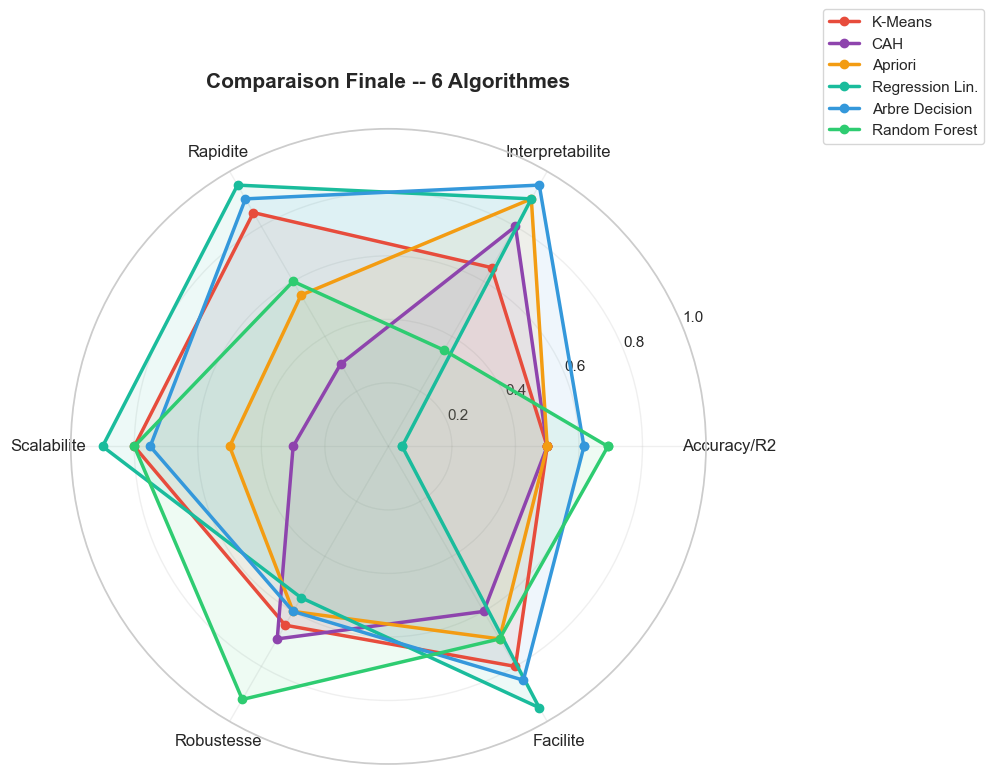

In [35]:
# Radar chart comparatif 6 algorithmes
categories_final = ['Accuracy/R2', 'Interpretabilite', 'Rapidite', 'Scalabilite', 'Robustesse', 'Facilite']
N_f = len(categories_final)

scores_final = {
    'K-Means'          : [0.50, 0.65, 0.85, 0.80, 0.65, 0.80],
    'CAH'              : [0.50, 0.80, 0.30, 0.30, 0.70, 0.60],
    'Apriori'          : [0.50, 0.90, 0.55, 0.50, 0.60, 0.70],
    'Regression Lin.'  : [r2,   0.90, 0.95, 0.90, 0.55, 0.95],
    'Arbre Decision'   : [acc_dt, 0.95, 0.90, 0.75, 0.60, 0.85],
    'Random Forest'    : [acc_rf, 0.35, 0.60, 0.80, 0.92, 0.70],
}

angles_f = np.linspace(0, 2*np.pi, N_f, endpoint=False).tolist() + [0]

fig, ax = plt.subplots(figsize=(11, 11), subplot_kw=dict(polar=True))
colors_f = ['#E74C3C','#8E44AD','#F39C12','#1ABC9C','#3498DB','#2ECC71']

for (algo, vals), color in zip(scores_final.items(), colors_f):
    vals_p = vals + [vals[0]]
    ax.plot(angles_f, vals_p, 'o-', linewidth=2.5, label=algo, color=color)
    ax.fill(angles_f, vals_p, alpha=0.08, color=color)

ax.set_xticks(angles_f[:-1])
ax.set_xticklabels(categories_final, fontsize=12)
ax.set_ylim(0, 1)
ax.set_title('Comparaison Finale -- 6 Algorithmes', fontsize=15, fontweight='bold', pad=30)
ax.legend(loc='upper right', bbox_to_anchor=(1.45, 1.2), fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Interprétation — Radar Chart Comparatif des 6 Algorithmes

Le radar chart permet d'évaluer simultanément **6 critères** pour chaque algorithme :
performance prédictive, interprétabilité, rapidité, scalabilité, robustesse et facilité d'implémentation.

---

### Algorithmes Non Supervisés

** K-Means**
Excellent équilibre entre rapidité et scalabilité → candidat idéal pour une mise en
production sur de grands catalogues musicaux. Faiblesse : sensibilité à l'initialisation
aléatoire des centroïdes.

** CAH**
Interprétabilité la plus élevée grâce au dendrogramme, qui permet de naviguer librement
dans la hiérarchie des clusters. Faiblesse majeure : complexité **O(n²)** qui la rend
impraticable sur de grands volumes.

** Apriori**
Sorties directement compréhensibles par des non-spécialistes et intégrables dans des
systèmes de recommandation sans transformation. Faiblesse : dépendance à la
discrétisation préalable des variables continues.

---

### Algorithmes Supervisés

** Régression Linéaire**
Modèle de référence : extrêmement rapide et parfaitement interprétable *(les coefficients
ont une signification directe)*. Insuffisamment performant **(R² ≈ 4%)** pour une
application en production, mais précieuse pour comprendre les directions d'influence
de chaque variable.

** Arbre de Décision**
Meilleur compromis **interprétabilité / performance** parmi les modèles supervisés.
Ses règles IF/ELSE peuvent être expliquées à des équipes non techniques. Faiblesse :
tendance à l'**overfitting** quand la profondeur n'est pas contrainte.

** Random Forest**
Algorithme le plus performant du projet en termes d'**accuracy et F1-Score**.
En combinant 100 arbres indépendants, il réduit la variance et améliore la
généralisation. Faiblesse : boîte noire difficile à interpréter directement.

---

### Tableau Récapitulatif

| Algorithme | Performance | Interprétabilité | Scalabilité | Recommandé pour |
|------------|------------|-----------------|-------------|-----------------|
| **K-Means** | Moyen | Moyen | Élevée | Segmentation production |
| **CAH** | Moyen |  Élevée |  Faible | Phase exploratoire |
| **Apriori** | Moyen |  Élevée | Moyenne | Recommandation |
| **Régression Lin.** |  Faible |  Élevée |  Élevée | Baseline / référence |
| **Arbre Décision** | Bon |  Élevée | Bonne | Explication métier |
| **Random Forest** |  Élevée |  Faible | Bonne | **Production** |

---

### Conclusion 

> Le **Random Forest** est recommandé pour la prédiction de popularité en production.
> La **CAH** et l'**Apriori** restent précieux en phase exploratoire.
> Le **K-Means** est idéal pour la segmentation du catalogue musical à grande échelle.

---
## 15. Conclusion Generale

# Conclusion Générale — Projet Data Mining Spotify

Ce projet a appliqué la méthodologie **CRISP-DM** à un dataset de **114 000 chansons Spotify**
comportant 21 variables audio et éditoriales, avec deux objectifs :
- Comprendre les structures latentes du catalogue musical *(approches non supervisées)*
- Prédire la popularité des chansons *(modèles supervisés)*

---

## Phase 1 — Préparation des Données

- Nettoyage : suppression des colonnes non pertinentes, traitement des valeurs manquantes,
  élimination des doublons et encodage des variables catégoriques
- **Normalisation Z-score** appliquée pour harmoniser les échelles — prérequis indispensable
  pour K-Means et la CAH
- **9 nouvelles variables** créées par feature engineering *(dance_score, positivity_score,
  energy_acoustic_ratio, duration_min, etc.)* pour capturer des combinaisons plus représentatives

---

## Phase 2 — Analyse Exploratoire

- **Corrélation forte** : `energy` ↔ `loudness` *(r ≈ 0.76)*
- **Corrélation inverse** : `acousticness` ↔ `energy` *(r ≈ -0.72)*
- **Corrélations faibles** avec la popularité *(rarement au-delà de 0.20)* → le succès
  commercial dépend largement de **facteurs extra-musicaux**
- Le **genre musical** est la variable la plus discriminante, encodant implicitement
  une combinaison complexe de caractéristiques acoustiques

---

## Phase 3 — Algorithmes Non Supervisés

| Algorithme | Résultat | Usage recommandé |
|------------|---------|-----------------|
| **K-Means** *(k=4)* | 4 archétypes : Énergique, Acoustique, Dansant, Instrumental | Segmentation production |
| **CAH** *(Ward, k=4)* | Partition similaire, validée par dendrogramme | Exploration initiale |
| **Apriori** | Règles actionnables reliant features audio et popularité | Système de recommandation |

---

## Phase 4 — Algorithmes Supervisés

| Algorithme | Performance | Rôle |
|------------|------------|------|
| **Régression Linéaire** | R² ≈ 4% | Baseline de référence |
| **Arbre de Décision** | Accuracy supérieure | Interprétabilité métier |
| **Random Forest** |  Meilleure performance | **Production** |

---

## Recommandations et Perspectives

### Architecture Opérationnelle Recommandée

| Besoin | Algorithme |
|--------|-----------|
| Segmentation du catalogue | **K-Means** *(rapidité, scalabilité)* |
| Système de recommandation | **Apriori + K-Means** *(règles + profils)* |
| Prédiction de popularité | **Random Forest** *(meilleure performance)* |
| Reporting métier | **Arbre de Décision** *(interprétabilité)* |
| Estimation continue | **Régression Linéaire** *(baseline)* |

### Pistes d'Amélioration

Pour améliorer les performances des modèles supervisés, les enrichissements
les plus prometteurs sont :
- La **notoriété de l'artiste** et son historique de streams
- Les **placements en playlist éditoriale**
- La **présence sur les réseaux sociaux**

> Ces variables extra-musicales sont probablement les principaux déterminants
> du succès commercial et leur intégration pourrait significativement améliorer
> le **R²** et l'**accuracy** des modèles.